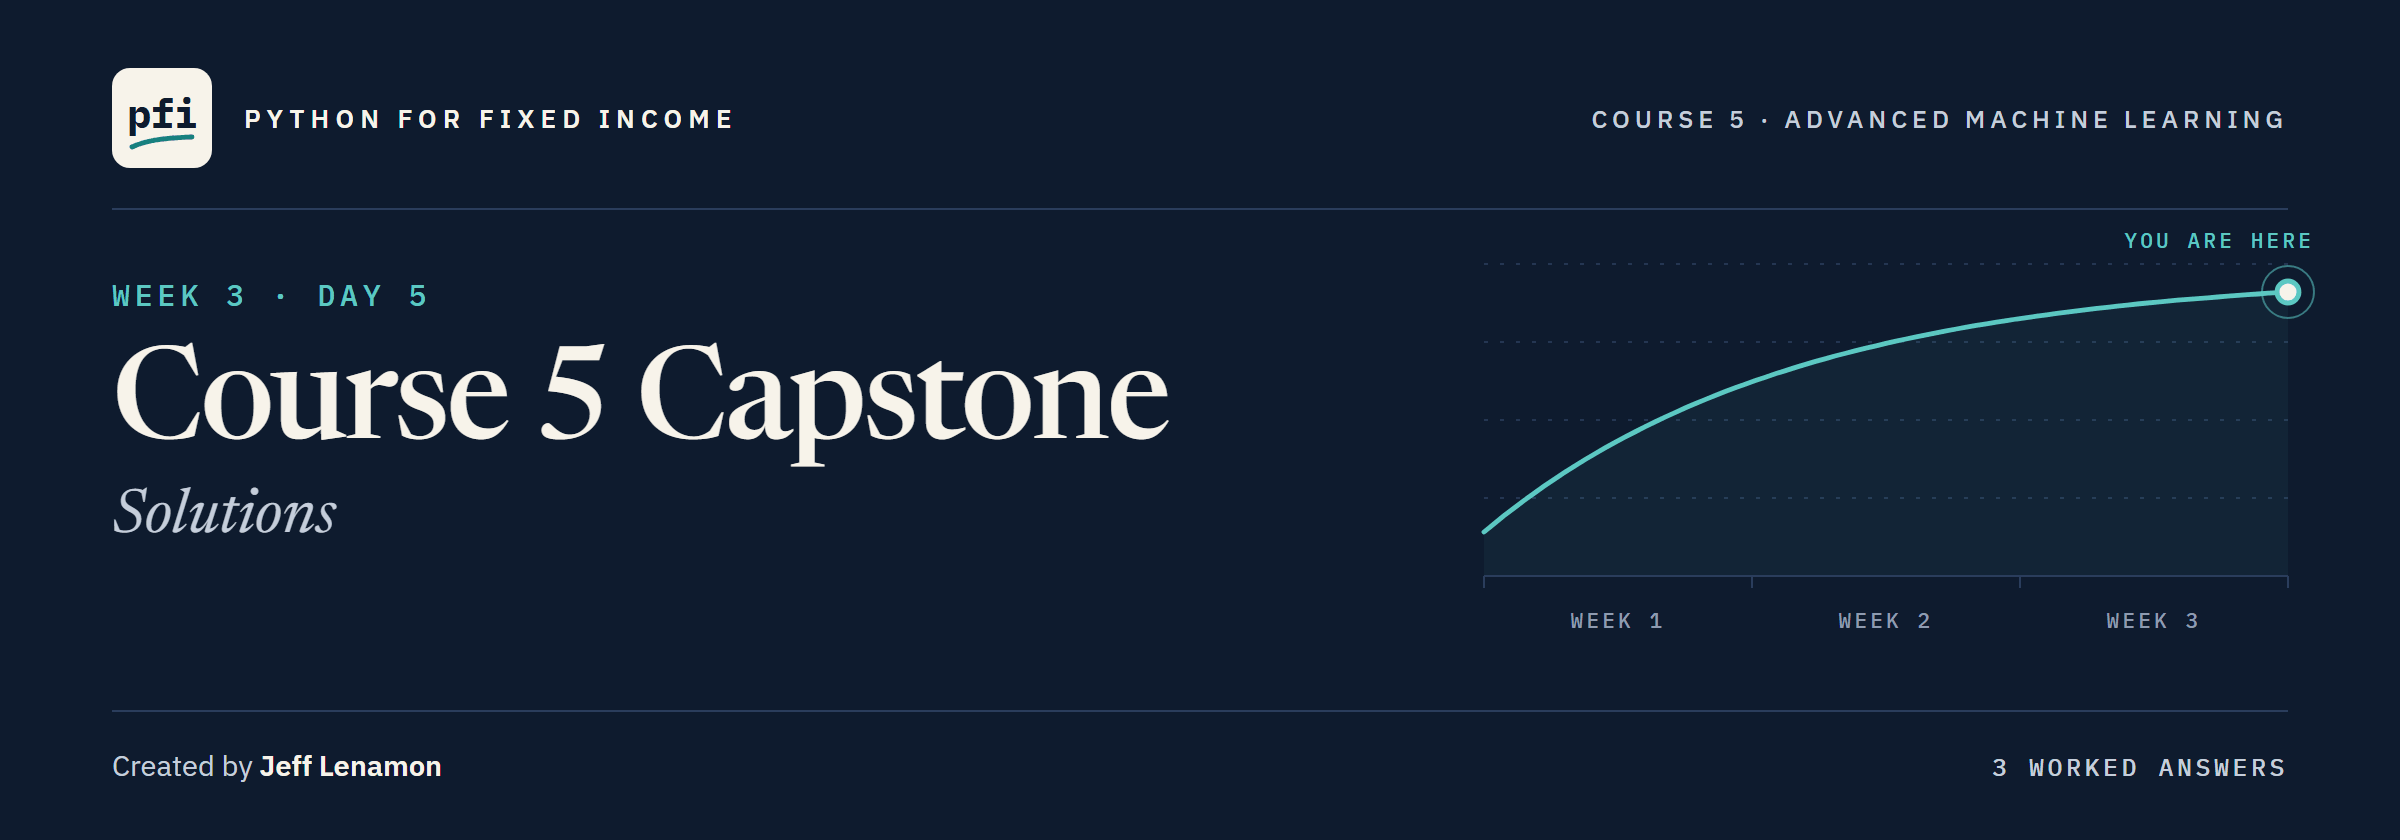

# Course 5 Capstone: Solutions

Week 3, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `taiwan_bankruptcy.csv`, 6,819 rows of company financial ratios from the Taiwan Economic Journal, 1999 to 2009: **real**, UCI Machine Learning Repository dataset 572, CC BY 4.0. Citation: Taiwanese Bankruptcy Prediction [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5004D.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day5/course5_capstone_solutions.ipynb)

# Problem Statement

## Business Context

A colleague who covers Asian corporates hands you a public file of Taiwanese companies' financial ratios, with a flag for the ones that went bankrupt.
The [dataset page](https://doi.org/10.24432/C5004D) says the data cover 1999 to 2009 and bankruptcy follows the Taiwan Stock Exchange's regulations, with no units, no horizon and no company identifier, so this notebook speaks of rows.
It is one market in one period, and that market differs from US credit.
She asks which of four models best separates bankrupt rows it never saw, how sure 44 bankrupt test rows let anyone be, and what the chosen model leans on.
Its output is "the model's probability of bankruptcy in this file", never a credit view on any company.
The work is yours: each question has an empty cell and a `check()` line.

## Objectives

Describe a new file's columns, copies and scales, and split it once.
Compare four models on folds, tune the leader honestly, and choose weights, resampling and a threshold out of fold.
Open the test rows once, put an interval on each score, and describe the chosen model with SHAP values on rows it never saw.

![The capstone on one page, in three sittings. Sitting one, the file: loading the data, the data overview, the exploratory analysis and the preparation. Sitting two, the models: model building, performance improvement and final model selection, with every setting, the treatment of the rare class and the threshold for a recall of 0.70 chosen on folds. Sitting three, the verdict: the test rows opened once, what the model leans on, where it fails, and the insights and conclusion. The test rows stay closed through sittings one and two.](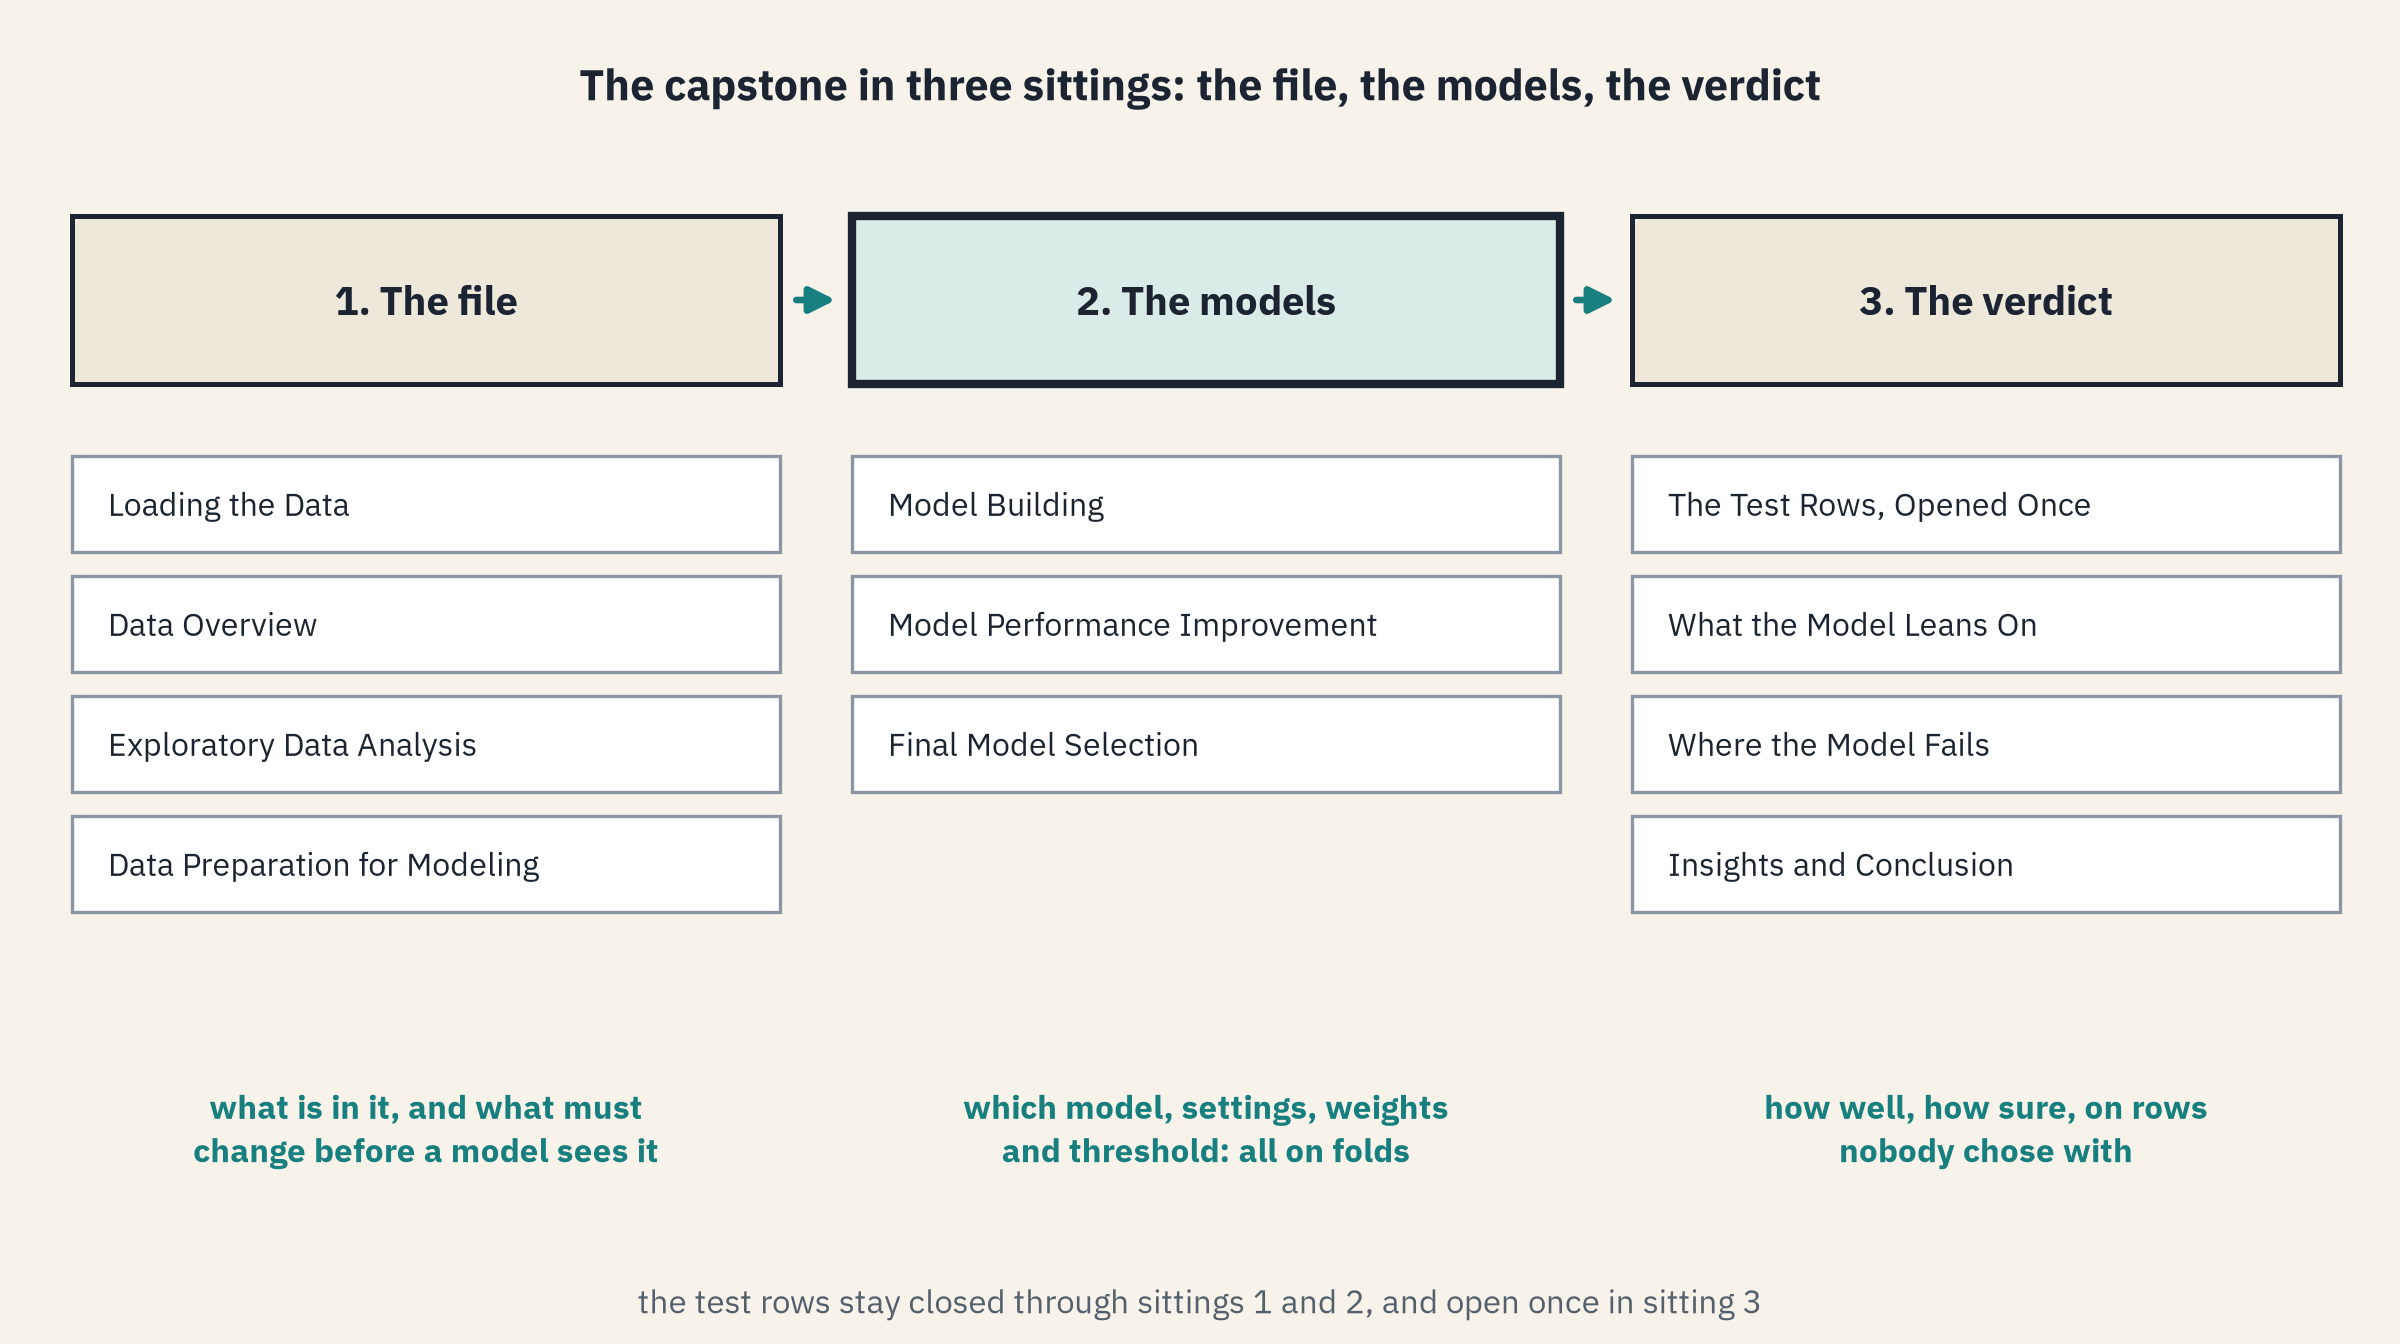)

## Data Dictionary

`taiwan_bankruptcy.csv`, one row per set of a company's ratios:

1. `Bankrupt?`: 1 if the company went bankrupt, **the target**
2. 95 features under their own names; the page's X1 to X95 list runs in another order, so it is quoted nowhere as a definition

The loader strips each name's leading space and the space and yen sign that end three names: the only changes to the file.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the half ellipse of an arc diagram
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Arc

# to split and fold the rows, score by folds, search, and score each row out of fold
from scipy.stats import randint, loguniform
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV

# the steps and the four models, the resampler and its pipeline, recalibration, and SHAP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import CalibratedClassifierCV
import shap

# to score flags, rankings and probabilities
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, brier_score_loss

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Course 4's colour for each of the four cells of a confusion matrix
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is written on the page.
A number is rounded to the places its question asks for, so you need not round it yourself.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

# Loading the Data

## Reading the File and Cleaning the Names

`"\u00a5"` is the yen sign written as an escape, a backslash, `u` and the character's four-digit code, so the cell stays plain ASCII.

In [4]:
# the 6,819 rows: the outcome first, then 95 features whose names start with a space
ratios = pd.read_csv(DATA + "taiwan_bankruptcy.csv")

# each name without its leading space, and without the space and yen sign that end three names
ratios.columns = [name.strip().replace(" \u00a5", "") for name in ratios.columns]
TARGET = "Bankrupt?"
FEATURES = [name for name in ratios.columns if name != TARGET]
print(len(FEATURES), "features; the three cleaned names:", [name for name in FEATURES if "Yuan" in name])

95 features; the three cleaned names: ['Revenue Per Share (Yuan)', 'Operating Profit Per Share (Yuan)', 'Per Share Net profit before tax (Yuan)']


# Data Overview

## Shape, Outcome and Copies

Q. How many rows does the file hold, how many are bankrupt, and what share is that in percent? Store them in `q1_rows`, `q1_bankrupt` and `q1_share` (2 decimals).

In [5]:
# the rows, the bankrupt rows, and their share in percent
q1_rows = len(ratios)
q1_bankrupt = ratios[TARGET].sum()
q1_share = ratios[TARGET].mean() * 100
print(q1_rows, "rows,", q1_bankrupt, "bankrupt,", round(q1_share, 2), "percent")

6819 rows, 220 bankrupt, 3.23 percent


220 of 6,819 rows are bankrupt, 3.23 percent: about half the Polish file's share on Days 11 to 14.

In [6]:
check("Q1 rows", q1_rows, "e0137fa498ca", places=0)
check("Q1 bankrupt rows", q1_bankrupt, "ca66b92568ac", places=0)
check("Q1 bankrupt share", q1_share, "04e9d7ba1266", places=2)

Q1 rows: correct
Q1 bankrupt rows: correct
Q1 bankrupt share: correct


Q. How many cells are empty, and how many rows repeat an earlier row, in full and in the features alone? Store them in `q2_empty`, `q2_copies` and `q2_feature_copies`.

In [7]:
# empty cells, rows that repeat an earlier row, and rows that repeat its features alone
q2_empty = ratios.isnull().sum().sum()
q2_copies = ratios.duplicated().sum()
q2_feature_copies = ratios[FEATURES].duplicated().sum()
print(q2_empty, "empty cells,", q2_copies, "copies,", q2_feature_copies, "rows repeating the features")

0 empty cells, 0 copies, 0 rows repeating the features


No gaps and no copies: no imputer and no row dropped.

In [8]:
check("Q2 empty cells", q2_empty, "d4a945dc91e1", places=0)
check("Q2 copies", q2_copies, "a7d13e02d4bb", places=0)
check("Q2 rows repeating the features", q2_feature_copies, "388d1dc7bb59", places=0)

Q2 empty cells: correct
Q2 copies: correct
Q2 rows repeating the features: correct


## Columns With One or Two Values

Q. Which feature holds one value in every row, and which exactly two? How many rows have the second at 1, and how many of those are bankrupt? Store them in `q3_constant`, `q3_two`, `q3_ones` and `q3_ones_bankrupt`.

In [9]:
# the distinct values in each feature, then the features with one and with two
distinct = ratios[FEATURES].nunique()
q3_constant = distinct[distinct == 1].index[0]
q3_two = distinct[distinct == 2].index[0]

# the rows where the two-valued feature is 1, and how many of them are bankrupt
ones = ratios[ratios[q3_two] == 1]
q3_ones, q3_ones_bankrupt = len(ones), ones[TARGET].sum()
print(q3_constant, "holds", ratios[q3_constant].unique(), "  ", q3_two, "is 1 in", q3_ones, "rows,", q3_ones_bankrupt, "bankrupt")

Net Income Flag holds [1]    Liability-Assets Flag is 1 in 8 rows, 6 bankrupt


`Net Income Flag` is 1 in every row, so it cannot tell one row from another.

`Liability-Assets Flag` is 1 in 8 rows, 6 of them bankrupt: eight rows are too few to read anything into.

**The constant goes; the flag stays, with eight rows behind it.**

In [10]:
check("Q3 constant feature", q3_constant, "0b578dd697f1")
check("Q3 two-valued feature", q3_two, "a67ae729391f")
check("Q3 rows at 1", q3_ones, "96207b24237e", places=0)
check("Q3 bankrupt rows at 1", q3_ones_bankrupt, "f6d3cb088a0a", places=0)

Q3 constant feature: correct
Q3 two-valued feature: correct
Q3 rows at 1: correct
Q3 bankrupt rows at 1: correct


## Columns That Repeat

`first.equals(second)` is `True` when two columns hold the same values in every row.

Q. How many pairs of features correlate above 0.99 in absolute value, how many of them are equal in every row, and how many features do they hold? Store them in `q4_near`, `q4_equal` and `q4_columns`.

An **arc diagram** joins related items on a line with arcs.
`Arc((x, 0), width, height, theta1=0, theta2=180)` draws a half ellipse centred at `x`, and `ax.add_patch()` places it.

Q. Draw one for the near pairs, the equal pairs dark.

In [11]:
# each pair of features once: the absolute correlations above the diagonal, as one Series
corr = ratios[FEATURES].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
near = pairs[pairs > 0.99]

# the near pairs equal in every row
equal = [(first, second) for first, second in near.index if ratios[first].equals(ratios[second])]

# every feature in the near pairs, each once, in the order the pairs name them
in_pairs = []
for pair in near.index:
    for name in pair:
        if name not in in_pairs:
            in_pairs.append(name)
q4_near, q4_equal, q4_columns = len(near), len(equal), len(in_pairs)
print(q4_near, "pairs above 0.99,", q4_equal, "equal in every row,", q4_columns, "features in them")
print(equal)

12 pairs above 0.99, 2 equal in every row, 18 features in them
[('Current Liabilities/Liability', 'Current Liability to Liability'), ('Current Liabilities/Equity', 'Current Liability to Equity')]


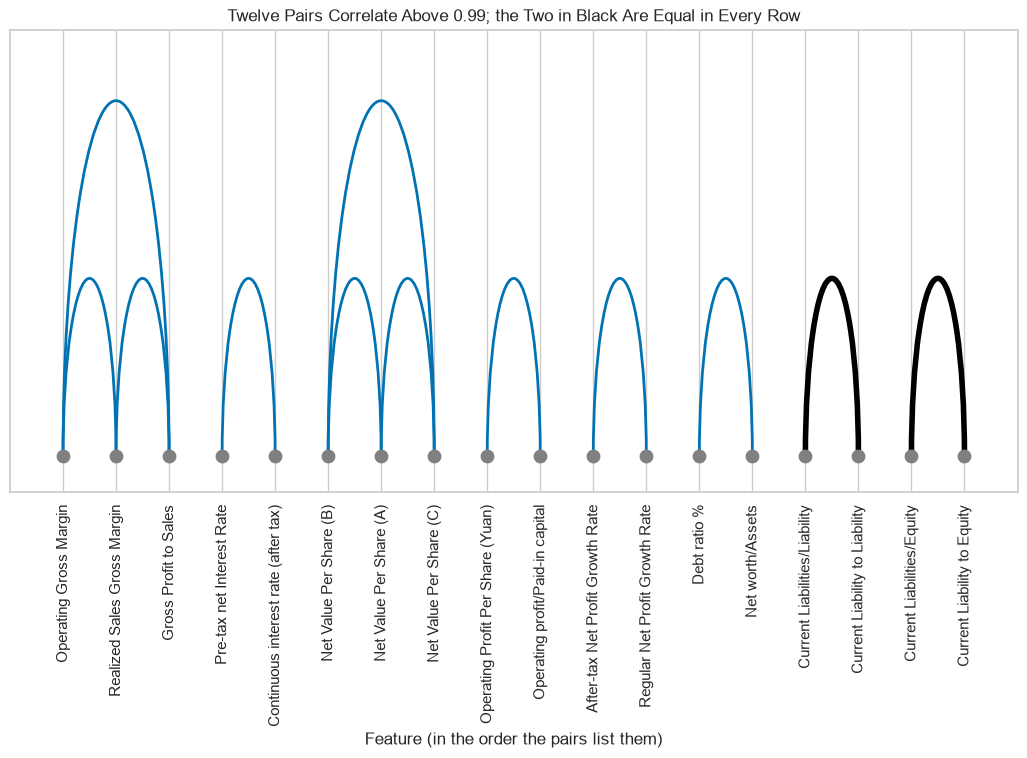

In [12]:
# each feature at a place on the line; each pair an arc from one place to the other, the equal pairs thick and dark
place = {name: spot for spot, name in enumerate(in_pairs)}
fig, ax = plt.subplots(figsize=(13, 6))
for (first, second), value in near.items():
    left, right = sorted([place[first], place[second]])
    dark = (first, second) in equal
    ax.add_patch(Arc(((left + right) / 2, 0), right - left, right - left, theta1=0, theta2=180,
                     color="black" if dark else "C0", linewidth=4 if dark else 2))
ax.scatter(range(len(in_pairs)), [0] * len(in_pairs), s=80, color="gray", zorder=3)
ax.set(xlim=(-1, len(in_pairs)), ylim=(-0.1, 1.2), yticks=[], xlabel="Feature (in the order the pairs list them)",
       title="Twelve Pairs Correlate Above 0.99; the Two in Black Are Equal in Every Row")
ax.set_xticks(range(len(in_pairs)), in_pairs, rotation=90)
plt.show()

`Current Liabilities/Liability` equals `Current Liability to Liability` in every row, and `Current Liabilities/Equity` equals `Current Liability to Equity`.

Ten more pairs move together above 0.99, 18 features in all.

**The second of each equal pair goes and the near-copies stay, remembering Day 14: a near-copy takes part of its partner's SHAP values.**

In [13]:
check("Q4 pairs above 0.99", q4_near, "553f8b823a65", places=0)
check("Q4 equal pairs", q4_equal, "4a128b55237f", places=0)
check("Q4 features in the pairs", q4_columns, "8a4e8815b180", places=0)

Q4 pairs above 0.99: correct
Q4 equal pairs: correct
Q4 features in the pairs: correct


## Two Scales in One Column

Q. How many features hold a value above 1? How many cells are above 1, and what are the smallest and the largest of them? Store them in `q5_columns`, `q5_cells`, `q5_smallest` and `q5_largest` (0 decimals each).

In [14]:
# the features with any value above 1, then every cell above 1 in them
over_one = [name for name in FEATURES if ratios[name].max() > 1]
values = ratios[over_one].to_numpy()
above = values[values > 1]
q5_columns, q5_cells, q5_smallest, q5_largest = len(over_one), len(above), above.min(), above.max()
print(q5_columns, "features,", q5_cells, "cells above 1, from", f"{q5_smallest:,.0f}", "to", f"{q5_largest:,.0f}")

24 features, 24940 cells above 1, from 583,000 to 10,000,000,000


In [15]:
check("Q5 features above 1", q5_columns, "19f6d584a978", places=0)
check("Q5 cells above 1", q5_cells, "24a37662c656", places=0)
check("Q5 smallest above 1", q5_smallest, "eb4f80c95200", places=0)
check("Q5 largest", q5_largest, "b904ec8ba279", places=0)

Q5 features above 1: correct
Q5 cells above 1: correct
Q5 smallest above 1: correct
Q5 largest: correct


## Every Value of Those Columns

A **broken axis** splits one axis into two panels with a gap between them, so values far apart sit on one chart.
In the code, `marker=[(-1, -1), (1, 1)]` draws each break mark as a short slash, and `clip_on=False` lets it sit across the panel's edge.

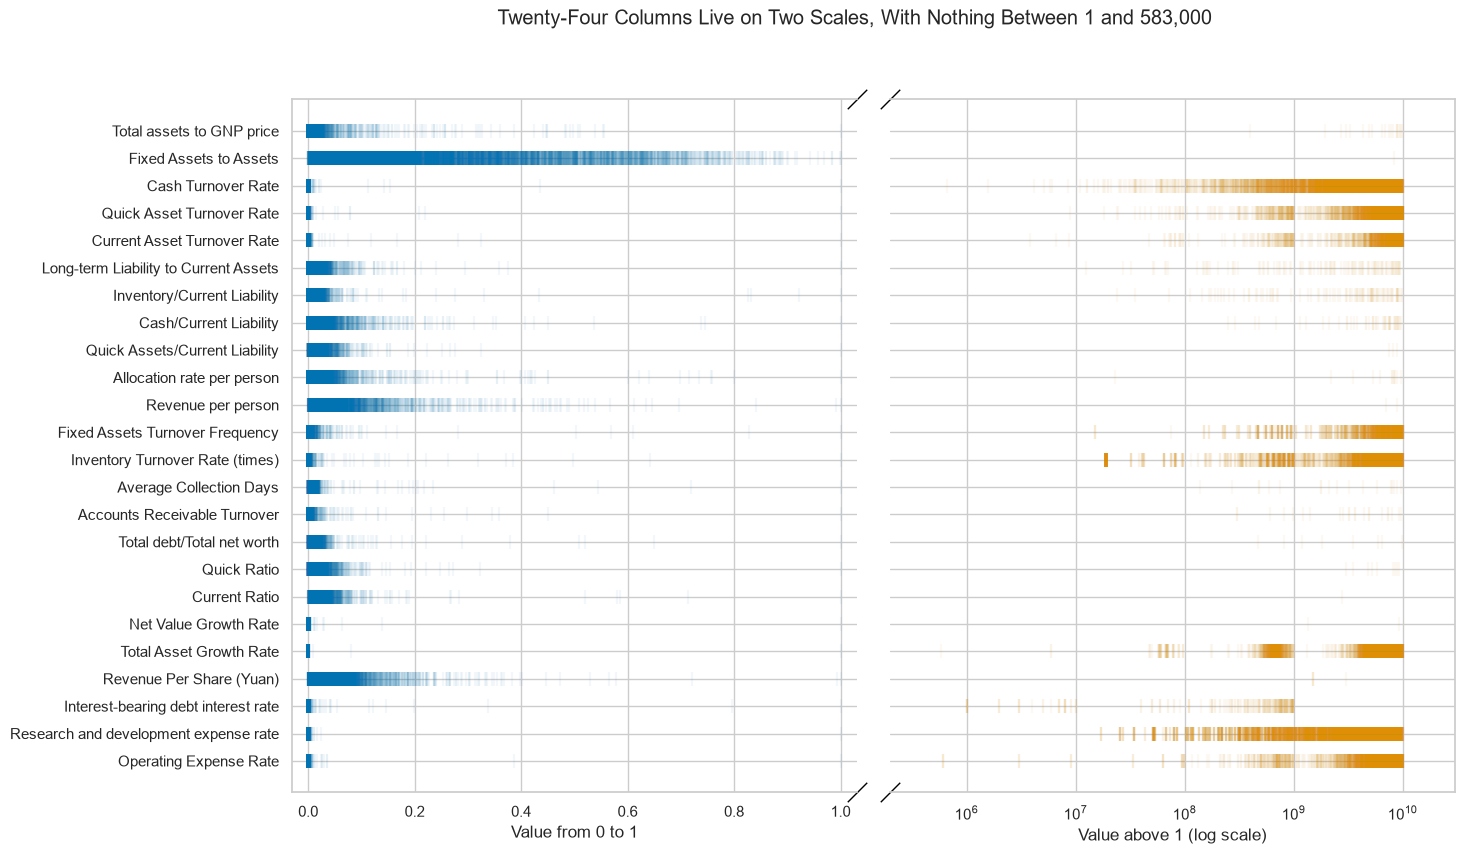

In [16]:
# the columns with a value above 1; each panel draws a column's values as ticks along its own row
wide = [name for name in FEATURES if ratios[name].max() > 1]
fig, (low, high) = plt.subplots(1, 2, sharey=True, figsize=(15, 9))
fig.subplots_adjust(wspace=0.06)  # a narrow gap between the two panels
for row, name in enumerate(wide):
    column = ratios[name]
    low.scatter(column[column <= 1], np.full((column <= 1).sum(), row), marker="|", s=100, alpha=0.05, color="C0")
    high.scatter(column[column > 1], np.full((column > 1).sum(), row), marker="|", s=100, alpha=0.05, color="C1")
low.set(xlim=(-0.03, 1.03), xlabel="Value from 0 to 1")
high.set(xscale="log", xlim=(2e5, 3e10), xlabel="Value above 1 (log scale)")
low.set_yticks(range(len(wide)), wide)
fig.suptitle("Twenty-Four Columns Live on Two Scales, With Nothing Between 1 and 583,000")

# the break: each facing edge hidden, and slashes at its ends (transAxes places a point by the panel's own 0 to 1)
for ax, x, edge in [(low, 1, "right"), (high, 0, "left")]:
    ax.spines[edge].set_visible(False)
    ax.plot([x, x], [0, 1], transform=ax.transAxes, marker=[(-1, -1), (1, 1)], markersize=14, linestyle="none", color="black", clip_on=False)
plt.show()

Most rows sit between 0 and 1, like the other 71 columns; the rest sit from 583,000 to 10 billion.

The page says nothing about the large values, so this notebook describes them and does not guess.

## Does the Scale Say Something?

Q. For `Total Asset Growth Rate` and `Cash Turnover Rate`, what percent of rows is bankrupt above 1, and at or below 1? Keep the four shares, their rows and Course 1's rough margin, 1.96 x sqrt(p x (1 - p) / n), in a table `by_scale`, and store the first column's two shares in `q6_above` and `q6_not` (2 decimals).

Q. Draw the four as dots with their margins as whiskers, the whole file's share dashed.

In [17]:
# for each column and each side of 1: the rows, the bankrupt share in percent, and Course 1's rough margin
rows = []
for name in ["Total Asset Growth Rate", "Cash Turnover Rate"]:
    for side, mask in [("above 1", ratios[name] > 1), ("0 to 1", ratios[name] <= 1)]:
        share = ratios.loc[mask, TARGET].mean()
        rows.append({"column": name, "side": side, "rows": mask.sum(), "share": share * 100,
                     "margin": 1.96 * np.sqrt(share * (1 - share) / mask.sum()) * 100})
by_scale = pd.DataFrame(rows)
q6_above, q6_not = by_scale.loc[0, "share"], by_scale.loc[1, "share"]
by_scale

,column,side,rows,share,margin
0,Total Asset Growth Rate,above 1,6017,3.5234,0.4659
1,Total Asset Growth Rate,0 to 1,802,0.9975,0.6878
2,Cash Turnover Rate,above 1,4239,4.3406,0.6134
3,Cash Turnover Rate,0 to 1,2580,1.3953,0.4526


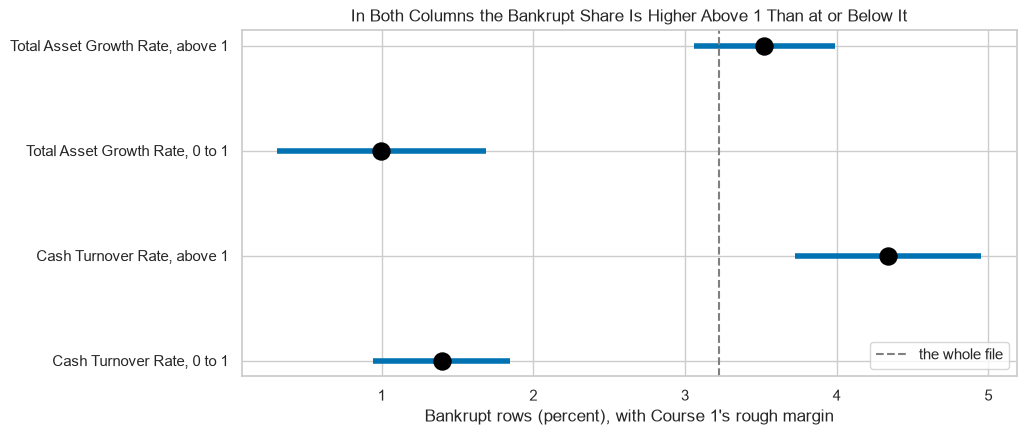

In [18]:
# each share as a dot with its margin as a whisker, the whole file's share dashed
labels = by_scale["column"] + ", " + by_scale["side"]
plt.figure(figsize=(10, 4.5))
plt.hlines(labels, by_scale["share"] - by_scale["margin"], by_scale["share"] + by_scale["margin"], linewidth=4)
plt.scatter(by_scale["share"], labels, s=150, color="black", zorder=3)
plt.axvline(ratios[TARGET].mean() * 100, color="gray", linestyle="--", label="the whole file")
plt.gca().invert_yaxis()
plt.xlabel("Bankrupt rows (percent), with Course 1's rough margin")
plt.title("In Both Columns the Bankrupt Share Is Higher Above 1 Than at or Below It")
plt.legend(loc="lower right")
plt.show()

Above 1 in `Total Asset Growth Rate`, 3.52 percent of 6,017 rows are bankrupt; at or below 1, 1.00 percent of 802.

`Cash Turnover Rate` shows the same direction, 4.34 against 1.40 percent, and neither pair of whiskers meets.

The file shows the difference and not why; a later question tests it as a feature.

In [19]:
check("Q6 share above 1", q6_above, "840591e46fcf", places=2)
check("Q6 share at or below 1", q6_not, "5ede3a6627f4", places=2)

Q6 share above 1: correct
Q6 share at or below 1: correct


**One constant, two equal pairs and two scales: the preparation drops three columns and learns any list it needs from the training rows.**

# Exploratory Data Analysis

**Predict 1**

Cut the file into ten slices in its own row order.

If the order meant nothing, each would hold about 22 of the 220 bankrupt rows.

Q. Sketch the ten counts you expect.

## The Order of the File

`np.array_split(values, 10)` cuts an array into ten slices, in order.

Q. Count the bankrupt rows in each tenth as a list of plain numbers (`int(...)` makes one) in `q7_tenths`, and store the position of the first operating row in `q7_first_operating`.

In [20]:
# the outcome in file order, cut into ten slices, and the bankrupt rows in each
q7_tenths = [int(piece.sum()) for piece in np.array_split(ratios[TARGET].to_numpy(), 10)]

# the first position where the outcome is 0
q7_first_operating = ratios.index[ratios[TARGET] == 0].min()
print("Bankrupt rows by tenth:", q7_tenths, "  First operating row:", q7_first_operating)

Bankrupt rows by tenth: [36, 30, 58, 34, 12, 9, 9, 10, 8, 14]   First operating row: 6


In [21]:
check("Q7 bankrupt rows by tenth", q7_tenths, "145cab6ffccc")
check("Q7 first operating row", q7_first_operating, "ff63aa731dc3", places=0)

Q7 bankrupt rows by tenth: correct
Q7 first operating row: correct


## The Bankrupt Rows Along the File

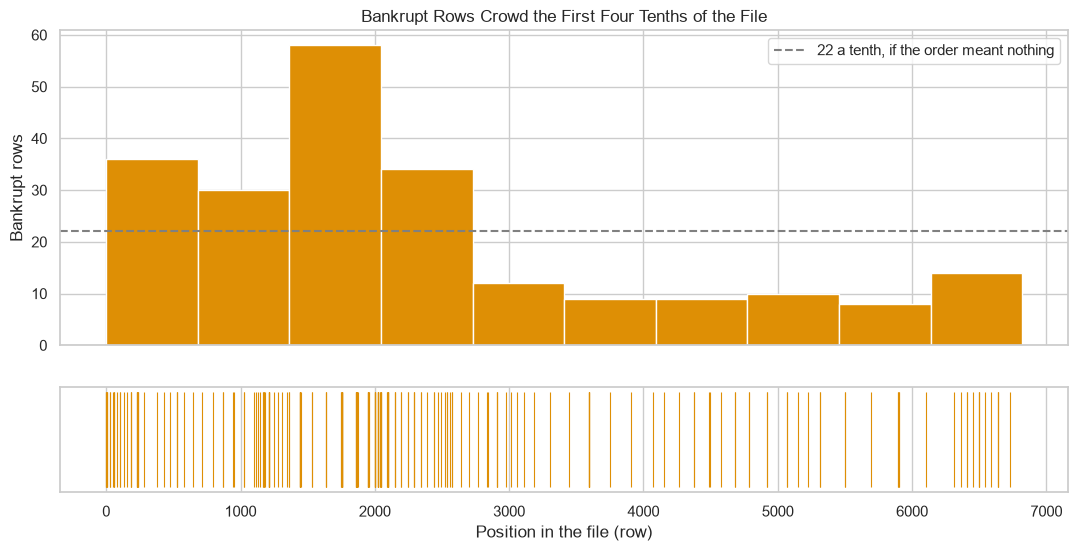

In [22]:
# the bankrupt rows per tenth as bars over the file's positions, and each bankrupt row as a tick underneath
edges = np.linspace(0, len(ratios), 11)
tenths = [piece.sum() for piece in np.array_split(ratios[TARGET].to_numpy(), 10)]
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(13, 6), height_ratios=[3, 1])
top.bar(edges[:-1], tenths, width=np.diff(edges), align="edge", color="C1", edgecolor="white")
top.axhline(22, color="gray", linestyle="--", label="22 a tenth, if the order meant nothing")
top.set(ylabel="Bankrupt rows", title="Bankrupt Rows Crowd the First Four Tenths of the File")
top.legend(loc="upper right")
bottom.vlines(ratios.index[ratios[TARGET] == 1], 0, 1, color="C1", linewidth=0.8)
bottom.set(yticks=[], xlabel="Position in the file (row)")
plt.show()

158 of the 220 sit in the first four tenths, and the first six rows are all bankrupt.

A split in file order would give the test rows another bankrupt share, so the split is shuffled and stratified, and position is never a feature.

## Debt by Outcome

Q. What is the median `Debt ratio %` of the bankrupt rows, and of the others? Store them in `q8_bankrupt` and `q8_operating` (4 decimals).

Q. Draw each outcome's `Debt ratio %` as an ECDF (Course 4's Day 6).

In [23]:
# the median Debt ratio % for each outcome
medians = ratios.groupby(TARGET)["Debt ratio %"].median()
q8_operating, q8_bankrupt = medians[0], medians[1]
medians

Bankrupt?
0   0.1094
1   0.1874
Name: Debt ratio %, dtype: float64

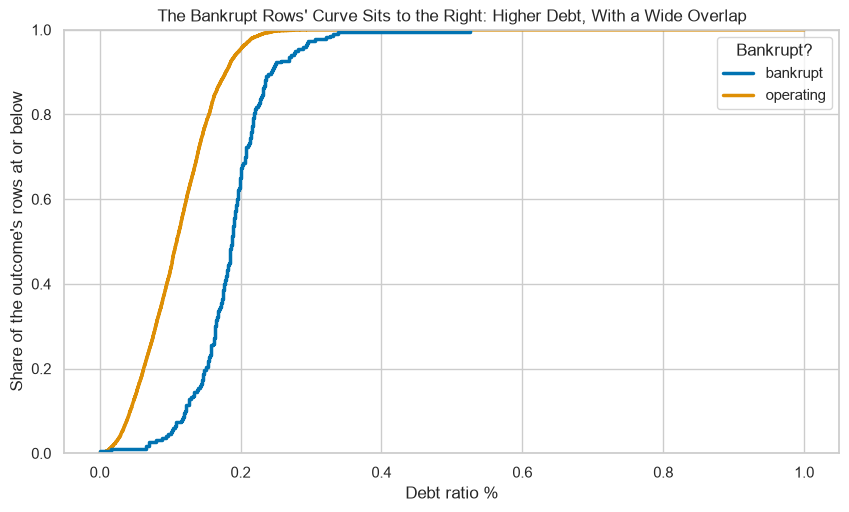

In [24]:
# each outcome's share of rows at or below every Debt ratio %
plt.figure(figsize=(10, 5.5))
sns.ecdfplot(x=ratios["Debt ratio %"], hue=ratios[TARGET].map({0: "operating", 1: "bankrupt"}), linewidth=2.5)
plt.xlabel("Debt ratio %")
plt.ylabel("Share of the outcome's rows at or below")
plt.title("The Bankrupt Rows' Curve Sits to the Right: Higher Debt, With a Wide Overlap")
plt.show()

The median `Debt ratio %` is 0.1874 for the bankrupt rows and 0.1094 for the others.

Each curve covers most of the other's range: one ratio will not separate the outcomes.

**So the models get all the features.**

In [25]:
check("Q8 median, bankrupt", q8_bankrupt, "8ef7dd720f31", places=4)
check("Q8 median, operating", q8_operating, "100833c0f5c8", places=4)

Q8 median, bankrupt: correct
Q8 median, operating: correct


# Data Preparation for Modeling

## Three Columns Out, Then One Split

Q. Drop the constant and the second feature of each equal pair, then split 80/20 into `X_train, X_test, y_train, y_test` with `stratify=y` and the course seed. Store the features left, the training rows and the training bankruptcies in `q9_features`, `q9_train_rows` and `q9_train_bankrupt`.

In [26]:
# the constant and the second of each equal pair out, then one stratified split
dropped = [q3_constant] + [second for first, second in equal]
X, y = ratios[FEATURES].drop(columns=dropped), ratios[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
q9_features, q9_train_rows, q9_train_bankrupt = X.shape[1], len(X_train), y_train.sum()
print("Dropped:", dropped)
print("Training:", len(X_train), "rows,", y_train.sum(), "bankrupt.  Test:", len(X_test), "rows,", y_test.sum(), "bankrupt")
print("Rows on both sides:", len(X_train.index.intersection(X_test.index)))

Dropped: ['Net Income Flag', 'Current Liability to Liability', 'Current Liability to Equity']
Training: 5455 rows, 176 bankrupt.  Test: 1364 rows, 44 bankrupt
Rows on both sides: 0


In [27]:
check("Q9 features", q9_features, "4b7385b8a143", places=0)
check("Q9 training rows", q9_train_rows, "b3e54af21628", places=0)
check("Q9 training bankruptcies", q9_train_bankrupt, "7b166db90baa", places=0)

Q9 features: correct
Q9 training rows: correct
Q9 training bankruptcies: correct


![The rows' roles. 6,819 rows, 220 bankrupt; the constant feature and the second of each equal pair dropped leaves 92 features. One stratified split, with the course seed: 5,455 training rows, 176 bankrupt, cut into five folds of 1,091 that fit, score and choose the model, every setting, the treatment of the rare class and the threshold. The 1,364 test rows, 44 bankrupt, stay closed until one model is chosen, then open once.](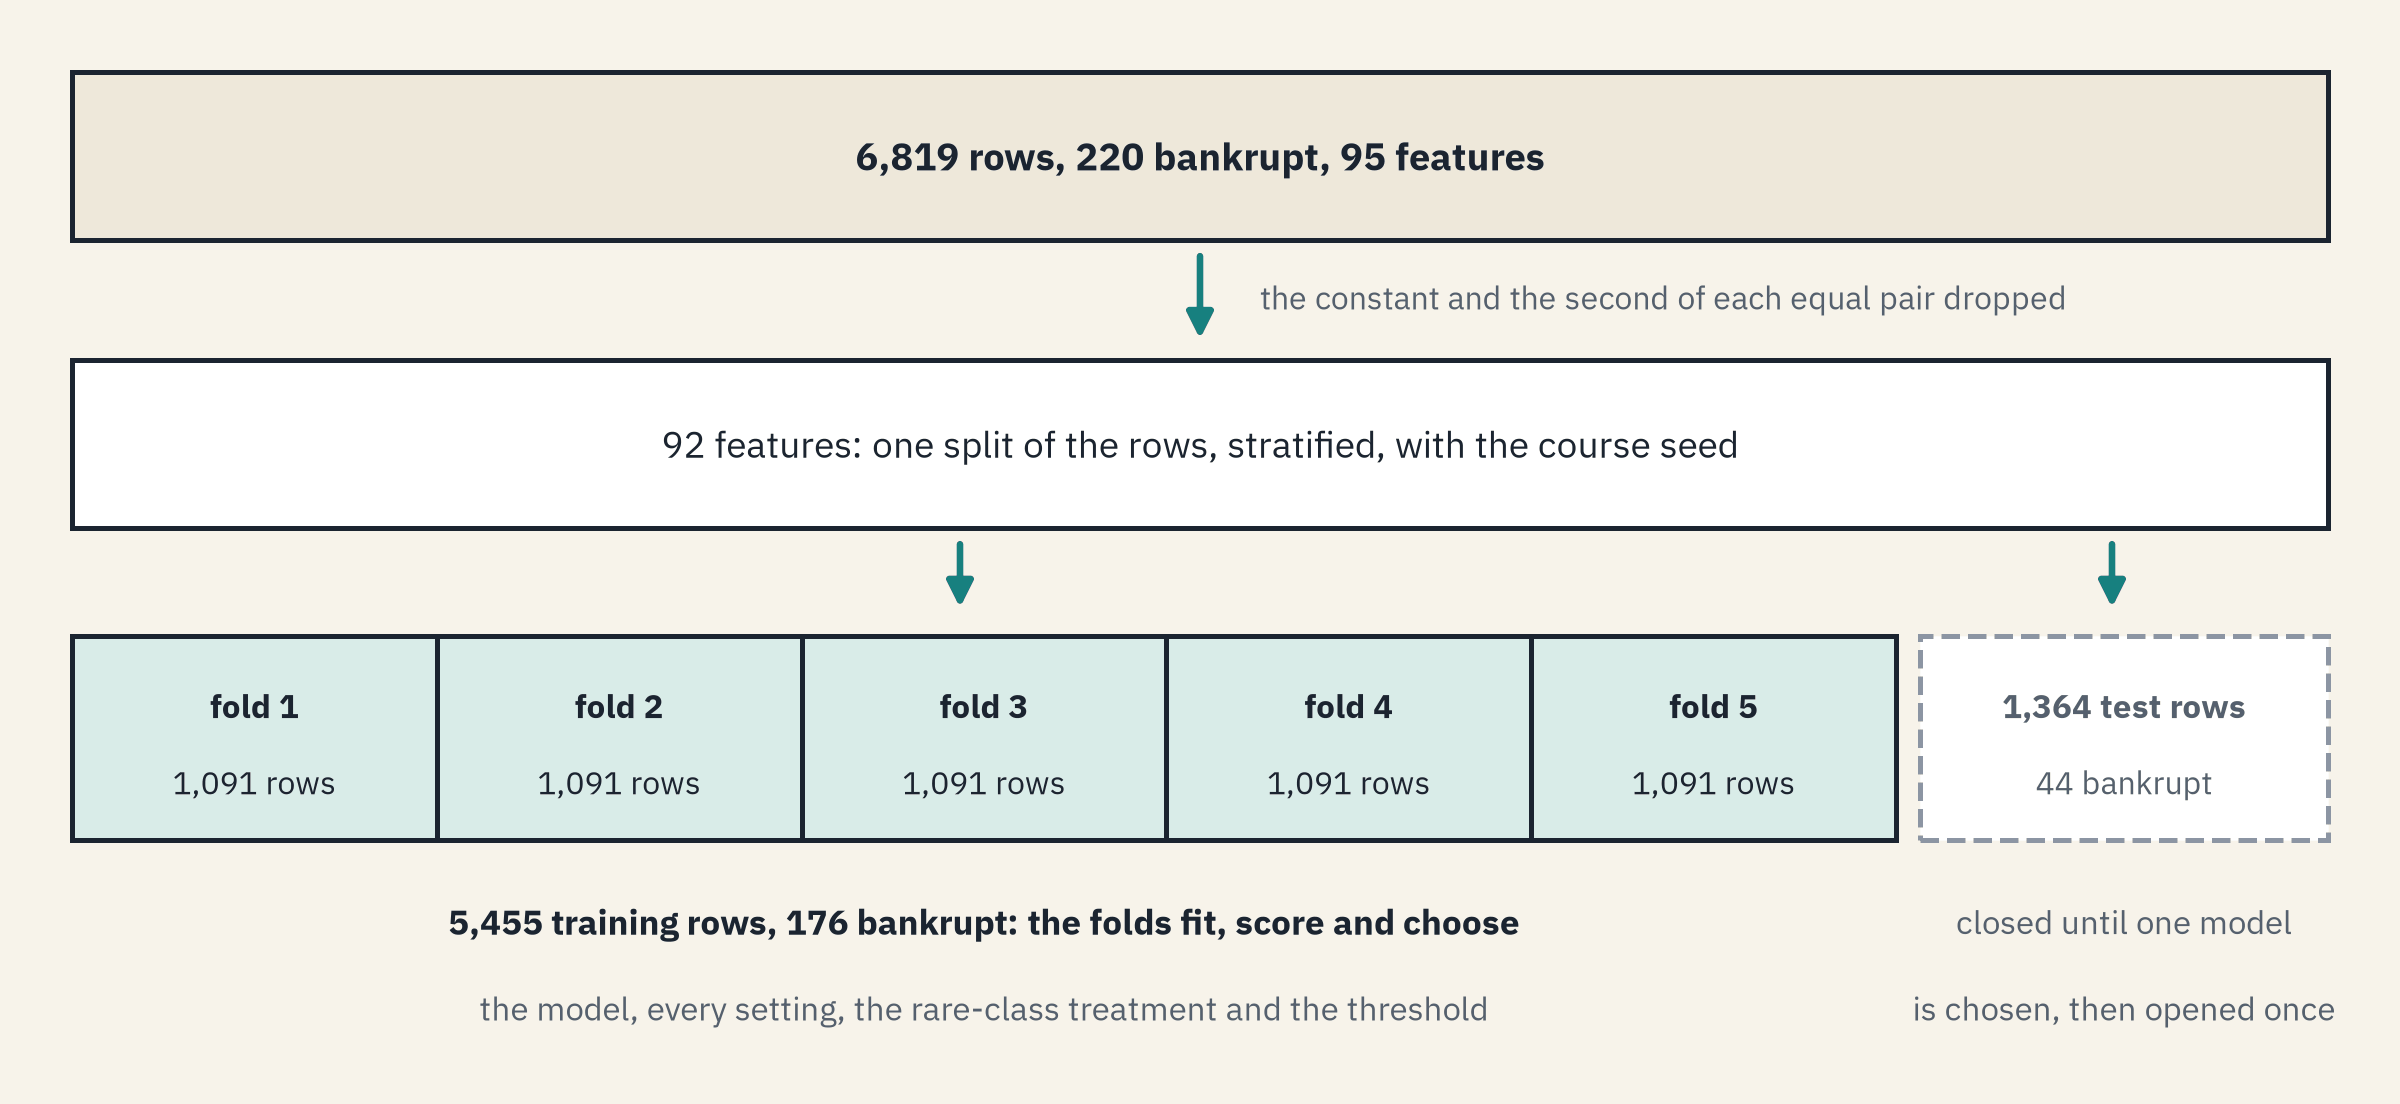)

**Every choice from here is made on the 5,455 training rows.**

## The Two-Scale List, From Training Rows

Q. Keep the features above 1 in the training rows in a list `two_scale`. Store how many in `q10_count`, and the one feature of the whole file's list missing from it in `q10_missing`.

In [28]:
# the features above 1 in the training rows: a later step uses this list, so it is learned from training rows only
two_scale = [name for name in X_train.columns if X_train[name].max() > 1]
q10_count = len(two_scale)
q10_missing = [name for name in over_one if name not in two_scale][0]
print(q10_count, "features; missing:", q10_missing)
print("Its largest value in the training rows:", X_train[q10_missing].max(), " in the test rows:", f"{X_test[q10_missing].max():,.0f}")

23 features; missing: Current Ratio
Its largest value in the training rows: 1.0  in the test rows: 2,750,000,000


`Current Ratio` holds one value above 1 in the whole file, and it fell among the test rows.

A list built on all 6,819 rows would have carried a fact from the test rows into training.

In [29]:
check("Q10 two-scale features", q10_count, "4bfd491865c4", places=0)
check("Q10 the feature missing", q10_missing, "abb8175dc22c")

Q10 two-scale features: correct
Q10 the feature missing: correct


# Model Building

## Model Evaluation Criterion

Flagging nobody is right about 97 percent of the time.

So models are ranked by **average precision** on five folds of the training rows (Course 4's capstone), ROC AUC beside it; a random ranking scores about 0.03.

Each gets a threshold for a recall of 0.70, the desk's illustration.

## The Folds and the Scoring Functions

Course 4's capstone scoring function with average precision first, and Day 10's threshold for a recall.

In [30]:
# five stratified folds of the training rows, shuffled with the course seed (Day 11's)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# flag at or above the threshold, then average precision, ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "Average precision": [average_precision_score(target, model.predict_proba(predictors)[:, 1])],
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

# the highest threshold whose recall on these outputs is at least the target
def threshold_for_recall(target, output, target_recall=0.70):
    precision, recall, thresholds = precision_recall_curve(target, output)
    return thresholds[recall[:-1] >= target_recall].max()

## Course 4's Logistic, Without Its Weights

Course 4's capstone logistic, without its imputer (no gaps here) or its class weights (Day 13 found the unweighted logistic ranks better).

Q. Build `logistic`, a pipeline of `QuantileTransformer(output_distribution="normal", random_state=SEED)` and `LogisticRegression(solver="newton-cholesky", tol=1e-8)` (steps `"quantile"`, `"logit"`), and score it with `cross_validate` on `folds`, scoring `["average_precision", "roc_auc"]`. Store the mean scores in `q11_ap` and `q11_auc` (4 decimals).

In [31]:
# Course 4's capstone logistic: normal scores, then the logistic regression, no weights
logistic = Pipeline([("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8))])
logistic_cv = cross_validate(logistic, X_train, y_train, cv=folds, scoring=["average_precision", "roc_auc"], n_jobs=1)
q11_ap, q11_auc = logistic_cv["test_average_precision"].mean(), logistic_cv["test_roc_auc"].mean()
print("Folds:", logistic_cv["test_average_precision"].round(4), " Average precision:", round(q11_ap, 4), " ROC AUC:", round(q11_auc, 4))

Folds: [0.3964 0.4227 0.3322 0.4336 0.4142]  Average precision: 0.3998  ROC AUC: 0.9321


Average precision 0.3998 and ROC AUC 0.9321 on rows each fold never saw, against about 0.03 for a ranking in random order.

**A model that ranks rows it never saw, on the first try.**

In [32]:
check("Q11 fold average precision", q11_ap, "bbb51b3dfc01", places=4)
check("Q11 fold ROC AUC", q11_auc, "944e1994707d", places=4)

Q11 fold average precision: correct
Q11 fold ROC AUC: correct


## Three Ensembles

To keep the run short, only the leader will be searched.

Q. Put four models in a dictionary `models` under `"logistic"`, `"forest"` (Day 3's random forest, here 100 trees with leaves of 5 rows or more), `"xgboost"` (XGBoost with two of Day 8's brakes, depth 3 and a step of 0.05, over 300 trees) and `"lightgbm"` (Day 11's LightGBM at its defaults), each with the seed and `n_jobs=1`. Keep each fold's average precision in a table `fold_ap`, one column per model. Store the ensembles' means in `q12_forest`, `q12_xgboost` and `q12_lightgbm` (4 decimals), and the folds where LightGBM beats the logistic in `q12_folds`.

Q. Draw each fold as a line across the models, the means in bold.

In [33]:
# the four models
models = {"logistic": logistic,
          "forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=SEED, n_jobs=1),
          "xgboost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED, n_jobs=1),
          "lightgbm": LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)}

# each model on the same five folds: every fold's average precision, and the mean ROC AUC
fold_ap, fold_auc = {}, {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring=["average_precision", "roc_auc"], n_jobs=1)
    fold_ap[name], fold_auc[name] = scores["test_average_precision"], scores["test_roc_auc"].mean()
fold_ap = pd.DataFrame(fold_ap)

In [34]:
# the mean, the spread across folds (NumPy's, as Day 11) and ROC AUC; then the folds LightGBM wins against each
q12_forest, q12_xgboost, q12_lightgbm = fold_ap["forest"].mean(), fold_ap["xgboost"].mean(), fold_ap["lightgbm"].mean()
q12_folds = (fold_ap["lightgbm"] > fold_ap["logistic"]).sum()
print("LightGBM higher on", {name: int((fold_ap["lightgbm"] > fold_ap[name]).sum()) for name in ["logistic", "forest", "xgboost"]}, "folds of 5")
pd.DataFrame({"fold AP": fold_ap.mean(), "fold sd": fold_ap.std(ddof=0), "ROC AUC": pd.Series(fold_auc)})

LightGBM higher on {'logistic': 5, 'forest': 3, 'xgboost': 4} folds of 5


,fold AP,fold sd,ROC AUC
logistic,0.3998,0.0359,0.9321
forest,0.4439,0.0469,0.9346
xgboost,0.4599,0.0743,0.9326
lightgbm,0.4785,0.0665,0.9400


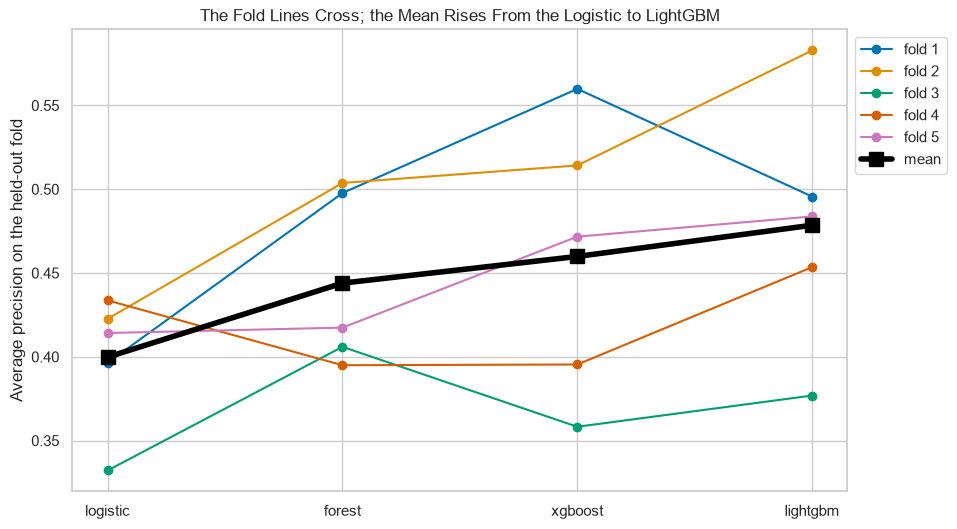

In [35]:
# one line per fold across the four models, the mean in bold
plt.figure(figsize=(10, 6))
for fold in fold_ap.index:
    plt.plot(fold_ap.columns, fold_ap.loc[fold], marker="o", linewidth=1.5, label=f"fold {fold + 1}")
plt.plot(fold_ap.columns, fold_ap.mean(), marker="s", markersize=10, linewidth=4, color="black", label="mean")
plt.ylabel("Average precision on the held-out fold")
plt.title("The Fold Lines Cross; the Mean Rises From the Logistic to LightGBM")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

LightGBM leads at 0.4785, then XGBoost 0.4599, the forest 0.4439 and the logistic 0.3998.

LightGBM beats the logistic on all five folds, but XGBoost on four and the forest on three.

The fold lines cross: one fold moves a model's score more than the gap between any two means.

**LightGBM leads XGBoost by 0.0186, under a third of its fold sd: the folds rank the models, they do not settle them.**

In [36]:
check("Q12 forest", q12_forest, "cfb35f5e18e5", places=4)
check("Q12 XGBoost", q12_xgboost, "c806a55d8aa6", places=4)
check("Q12 LightGBM", q12_lightgbm, "8501a9215b44", places=4)
check("Q12 folds LightGBM beats the logistic", q12_folds, "af6bb19bdcf8", places=0)

Q12 forest: correct
Q12 XGBoost: correct
Q12 LightGBM: correct
Q12 folds LightGBM beats the logistic: correct


# Model Performance Improvement

## Indicators for the Two Scales

Q. Write `add_above_one(frame)`, returning the frame plus a 0/1 column per feature in `two_scale`, 1 above 1. Put it in Day 12's `FunctionTransformer` as step `"above"` before the logistic's two steps, and score it on `folds`. Store its mean in `q13_ap` (4 decimals) and the folds where it beats the logistic in `q13_folds`.

In [37]:
# the 0/1 columns, named by add_suffix and added beside the features: a step that learns nothing
def add_above_one(frame):
    return pd.concat([frame, (frame[two_scale] > 1).astype(int).add_suffix(" above 1")], axis=1)

with_flags = Pipeline([("above", FunctionTransformer(add_above_one)),
                       ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                       ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8))])
flag_scores = cross_validate(with_flags, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)["test_score"]
q13_ap, q13_folds = flag_scores.mean(), (flag_scores > fold_ap["logistic"].to_numpy()).sum()
print("Average precision:", round(q13_ap, 4), " higher than the logistic on", q13_folds, "folds of 5")

Average precision: 0.4041  higher than the logistic on 2 folds of 5


0.4041 against 0.3998, higher on 2 folds of 5: a gain far inside the fold spread.

The quantile transform already gives every value above 1 a higher normal score than any value at or below 1, so the logistic could see the two scales before.

**The logistic keeps its two steps.**

In [38]:
check("Q13 fold average precision", q13_ap, "69bdff75f4fc", places=4)
check("Q13 folds it beats the logistic", q13_folds, "c4972029744c", places=0)

Q13 fold average precision: correct
Q13 folds it beats the logistic: correct


## A Random Search for LightGBM

Q. Search Day 11's space for `models["lightgbm"]` (`num_leaves` from `randint(8, 32)`, `learning_rate` from `loguniform(0.03, 0.3)`) with `RandomizedSearchCV(..., n_iter=6, scoring="average_precision", cv=folds, random_state=SEED, n_jobs=1)`, as `search`. Store the best leaves, rate and `best_score_` in `q14_leaves`, `q14_rate` and `q14_best` (4 decimals).

Q. Draw Day 11's search-space scatter, the defaults (31 leaves, 0.1) as a cross.

In [39]:
# six candidates from Day 11's space, each scored on the five folds
space = {"num_leaves": randint(8, 32), "learning_rate": loguniform(0.03, 0.3)}
search = RandomizedSearchCV(models["lightgbm"], space, n_iter=6, scoring="average_precision", cv=folds, random_state=SEED, n_jobs=1)
search.fit(X_train, y_train)
q14_leaves, q14_rate, q14_best = search.best_params_["num_leaves"], search.best_params_["learning_rate"], search.best_score_

# the candidates, best first
candidates = pd.DataFrame(search.cv_results_["params"])
candidates["fold AP"] = search.cv_results_["mean_test_score"]
candidates.sort_values("fold AP", ascending=False)

,learning_rate,num_leaves,fold AP
1,0.1619,28,0.4834
0,0.0711,22,0.4503
2,0.0430,26,0.4458
3,0.0378,18,0.4456
5,0.0417,10,0.4255
4,0.2204,11,0.4160


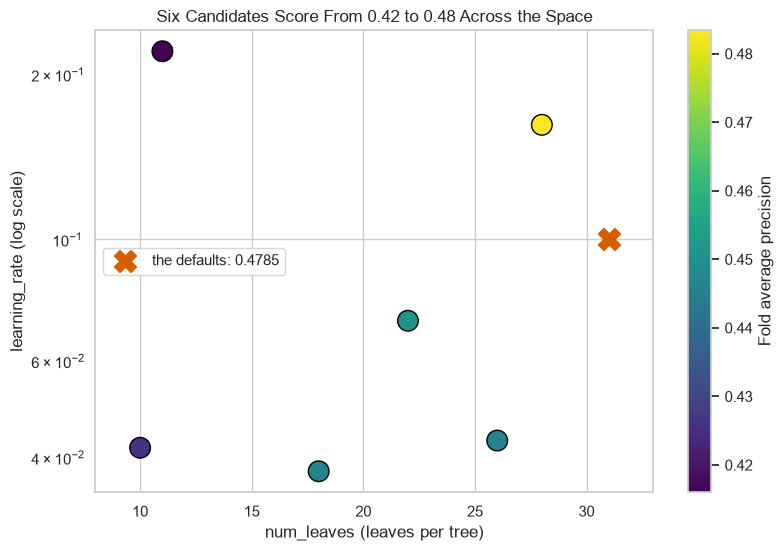

In [40]:
# each candidate at its settings, coloured by its fold score; the defaults as a cross
plt.figure(figsize=(9, 6))
dots = plt.scatter(candidates["num_leaves"], candidates["learning_rate"], c=candidates["fold AP"], cmap="viridis", s=220, edgecolor="black")
plt.scatter(31, 0.1, marker="X", s=250, color="C3", label="the defaults: 0.4785")
plt.colorbar(dots, label="Fold average precision")
plt.yscale("log")
plt.xlabel("num_leaves (leaves per tree)")
plt.ylabel("learning_rate (log scale)")
plt.title("Six Candidates Score From 0.42 to 0.48 Across the Space")
plt.xlim(8, 33)
plt.legend(loc="center left")
plt.show()

The best candidate, 28 leaves at a rate of 0.1619, scores 0.4834 on the folds that chose it, 0.0049 above the defaults.

The other five all score below the defaults, from 0.4160 to 0.4503.

In [41]:
check("Q14 best leaves", q14_leaves, "4190ce351f8e", places=0)
check("Q14 best rate", q14_rate, "ad1ff9205f0c", places=4)
check("Q14 best fold score", q14_best, "5ebf38c2701d", places=4)

Q14 best leaves: correct
Q14 best rate: correct
Q14 best fold score: correct


**Predict 2**

The search's best scores 0.4834 on the folds that chose it, and the defaults 0.4785.

Q. Run the whole search inside each fold, as Day 11 did, and score each winner on the fold it never saw. What will the mean be? Write down a number.

## The Search, Scored Honestly

Q. Score `inner_search`, the same search on `StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)`, with Day 11's nested `cross_validate(..., cv=folds, return_estimator=True, n_jobs=1)`. Store the outer mean in `q15_nested` (4 decimals) and the number of different winners in `q15_winners`.

In [42]:
# the search runs on three inner folds inside each outer training part; the outer fold scores its winner once
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
inner_search = RandomizedSearchCV(models["lightgbm"], space, n_iter=6, scoring="average_precision", cv=inner, random_state=SEED, n_jobs=1)
nested = cross_validate(inner_search, X_train, y_train, cv=folds, scoring="average_precision", return_estimator=True, n_jobs=1)

# each outer fold's winner and its score there
winners = pd.DataFrame([fitted.best_params_ for fitted in nested["estimator"]])
winners["outer fold"] = nested["test_score"]
q15_nested, q15_winners = nested["test_score"].mean(), len(winners[["learning_rate", "num_leaves"]].drop_duplicates())
print("Nested score:", round(q15_nested, 4), "  Different winners:", q15_winners)
winners

Nested score: 0.4491   Different winners: 4


,learning_rate,num_leaves,outer fold
0,0.1619,28,0.4986
1,0.0711,22,0.5642
2,0.0430,26,0.3462
3,0.0378,18,0.4048
4,0.0378,18,0.4317


Scored on folds it never chose with, the search lands at 0.4491, below the defaults' 0.4785, and its outer folds run from 0.3462 to 0.5642.

Five outer folds pick four different winners: the best of six candidates is mostly the luck of the folds that chose it.

**The defaults go forward, Day 11's rule.**

In [43]:
check("Q15 nested score", q15_nested, "70214d3e8f86", places=4)
check("Q15 different winners", q15_winners, "14d8a905a382", places=0)

Q15 nested score: correct
Q15 different winners: correct


## Weights, SMOTE, or Neither

Q. Score LightGBM two more ways on `folds`, both Day 13's: `class_weight="balanced"`, and `SMOTE(random_state=SEED)` before it in an `ImbPipeline` (steps `"smote"`, `"lightgbm"`). Keep the three versions in `versions` (`"neither"`, `"balanced"`, `"smote"`) and their fold scores in a table `version_ap`. Store the new means in `q16_balanced` and `q16_smote` (4 decimals).

Q. Draw the means as bars, the fold scores as dots.

In [44]:
# LightGBM three ways: as it is, with balanced class weights, and after SMOTE inside each fold's training part
versions = {"neither": models["lightgbm"],
            "balanced": LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=1, verbose=-1),
            "smote": ImbPipeline([("smote", SMOTE(random_state=SEED)), ("lightgbm", LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1))])}
version_ap = pd.DataFrame({"neither": fold_ap["lightgbm"]})
for name in ["balanced", "smote"]:
    version_ap[name] = cross_validate(versions[name], X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)["test_score"]
q16_balanced, q16_smote = version_ap["balanced"].mean(), version_ap["smote"].mean()
version_ap.mean()

neither    0.4785
balanced   0.4674
smote      0.4773
dtype: float64

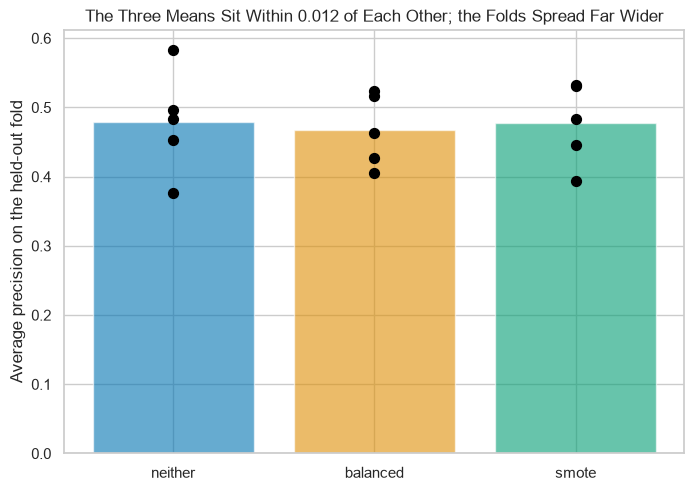

In [45]:
# each version's mean as a bar, its five folds as dots on it
plt.figure(figsize=(8, 5.5))
plt.bar(version_ap.columns, version_ap.mean(), color=["C0", "C1", "C2"], alpha=0.6)
for spot, name in enumerate(version_ap.columns):
    plt.scatter([spot] * 5, version_ap[name], color="black", s=50, zorder=3)
plt.ylabel("Average precision on the held-out fold")
plt.title("The Three Means Sit Within 0.012 of Each Other; the Folds Spread Far Wider")
plt.show()

0.4785 as it is, 0.4674 with balanced weights, 0.4773 with SMOTE: within 0.012, while each version's folds spread far wider.

In [46]:
check("Q16 balanced", q16_balanced, "e125211f8f65", places=4)
check("Q16 SMOTE", q16_smote, "db6fdca3b391", places=4)

Q16 balanced: correct
Q16 SMOTE: correct


Q. Score each version out of fold with `cross_val_predict(..., method="predict_proba")` and read its threshold for a recall of 0.70. In a table `at_70`, give each its threshold, rows flagged, their precision and its mean output, and store the flags in `q17_neither`, `q17_balanced` and `q17_smote`.

In [47]:
# each version's out-of-fold outputs, then its threshold, flags, precision and mean output
outputs, rows = {}, []
for name, version in versions.items():
    outputs[name] = cross_val_predict(version, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    threshold = threshold_for_recall(y_train, outputs[name])
    flags = outputs[name] >= threshold
    rows.append({"threshold": threshold, "flagged": flags.sum(), "precision": precision_score(y_train, flags), "mean output": outputs[name].mean()})
at_70 = pd.DataFrame(rows, index=list(versions))
q17_neither, q17_balanced, q17_smote = at_70["flagged"]
print("Bankrupt share of the training rows:", round(y_train.mean(), 4))
at_70

Bankrupt share of the training rows: 0.0323


,threshold,flagged,precision,mean output
neither,0.0039,374,0.3316,0.0139
balanced,0.0241,393,0.3155,0.0269
smote,0.1186,378,0.3280,0.0423


For a recall of 0.70 the unweighted model flags 374 rows, the fewest, and 33.2 percent of them are bankrupt.

Its probabilities average 0.0139 against a bankrupt share of 0.0323, while the weighted and resampled models' scores average 0.0269 and 0.0423: both raise the outputs, and neither ranks better.

**Day 13's finding holds here: the untuned, unweighted LightGBM goes into the final round.**

In [48]:
check("Q17 flagged, neither", q17_neither, "fd564570a727", places=0)
check("Q17 flagged, balanced", q17_balanced, "d20469d99c08", places=0)
check("Q17 flagged, SMOTE", q17_smote, "8ed29cd42134", places=0)

Q17 flagged, neither: correct
Q17 flagged, balanced: correct
Q17 flagged, SMOTE: correct


# Final Model Selection

The criterion was set before any model was fitted: fold average precision first.

## Thresholds for a Recall of 0.70

Q. Keep the four models' out-of-fold outputs in a dictionary `out_of_fold` (LightGBM's are `outputs["neither"]`) and their thresholds for 0.70 in `thresholds`. Store the logistic's, forest's and XGBoost's in `q18_logistic`, `q18_forest` and `q18_xgboost` (4 decimals).

Q. Draw the four out-of-fold precision-recall curves, recall 0.70 dashed, each threshold a dot.

In [49]:
# each model's out-of-fold outputs (LightGBM's already scored), then its threshold for a recall of 0.70
out_of_fold = {"lightgbm": outputs["neither"]}
for name in ["logistic", "forest", "xgboost"]:
    out_of_fold[name] = cross_val_predict(models[name], X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
thresholds = {name: threshold_for_recall(y_train, out_of_fold[name]) for name in models}
q18_logistic, q18_forest, q18_xgboost = thresholds["logistic"], thresholds["forest"], thresholds["xgboost"]

# the threshold, the training rows flagged, and their precision, model by model
summary = pd.DataFrame({"threshold": thresholds})
summary["flagged"] = [(out_of_fold[name] >= thresholds[name]).sum() for name in models]
summary["precision"] = [precision_score(y_train, out_of_fold[name] >= thresholds[name]) for name in models]
summary

,threshold,flagged,precision
logistic,0.0901,447,0.2774
forest,0.1325,420,0.2952
xgboost,0.0785,382,0.3246
lightgbm,0.0039,374,0.3316


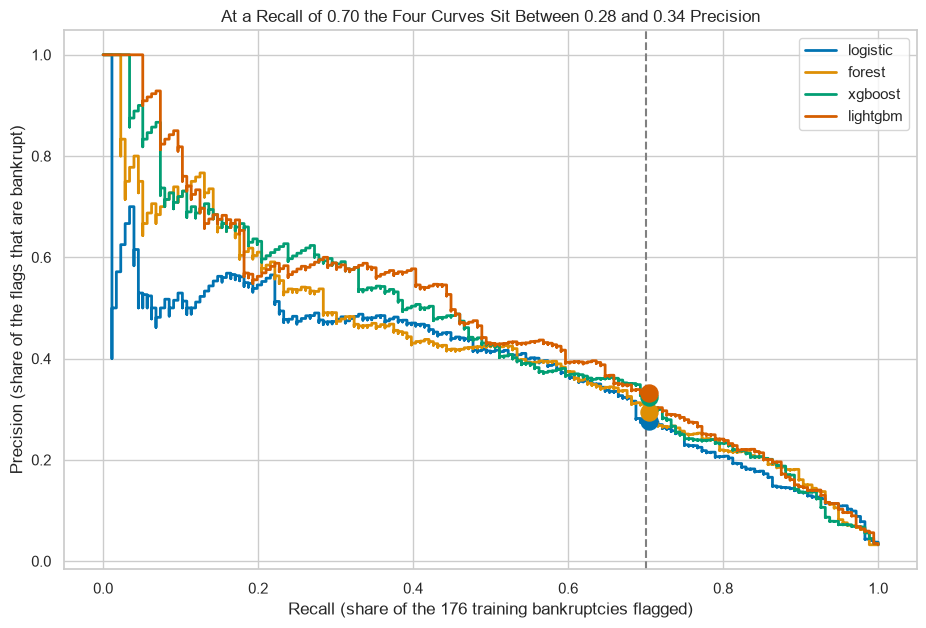

In [50]:
# each model's out-of-fold precision-recall curve, a dot where its threshold for 0.70 lands
plt.figure(figsize=(11, 7))
for number, name in enumerate(models):
    precision, recall, cuts = precision_recall_curve(y_train, out_of_fold[name])
    plt.plot(recall, precision, drawstyle="steps-post", linewidth=2, color=f"C{number}", label=name)
    plt.scatter(recall_score(y_train, out_of_fold[name] >= thresholds[name]), summary.loc[name, "precision"], s=150, color=f"C{number}", zorder=3)
plt.axvline(0.70, color="gray", linestyle="--")
plt.xlabel("Recall (share of the 176 training bankruptcies flagged)")
plt.ylabel("Precision (share of the flags that are bankrupt)")
plt.title("At a Recall of 0.70 the Four Curves Sit Between 0.28 and 0.34 Precision")
plt.legend(loc="upper right")
plt.show()

To catch 70 percent of the 176 training bankruptcies LightGBM flags 374 rows, XGBoost 382, the forest 420 and the logistic 447.

LightGBM reaches the recall at a threshold of 0.0039, far below the others' 0.08 to 0.13.

In [51]:
check("Q18 logistic threshold", q18_logistic, "e9a3d18701ae", places=4)
check("Q18 forest threshold", q18_forest, "c90ab6c70f60", places=4)
check("Q18 XGBoost threshold", q18_xgboost, "796b227db313", places=4)

Q18 logistic threshold: correct
Q18 forest threshold: correct
Q18 XGBoost threshold: correct


## Judged on Their Own Rows

Q. Fit each model on all the training rows and score it there. Set that score beside its fold mean in a table `gap_table`, and store LightGBM's and the logistic's in `q19_lightgbm` and `q19_logistic` (4 decimals).

Q. Draw each model as a dumbbell from its fold mean to its training-row score.

In [52]:
# each model fitted on every training row, then scored on those rows, beside its fold mean
own = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    own[name] = average_precision_score(y_train, model.predict_proba(X_train)[:, 1])
gap_table = pd.DataFrame({"training rows": own, "folds": fold_ap.mean()})
q19_lightgbm, q19_logistic = gap_table.loc["lightgbm", "training rows"], gap_table.loc["logistic", "training rows"]
gap_table

,training rows,folds
logistic,0.5531,0.3998
forest,0.9470,0.4439
xgboost,0.9893,0.4599
lightgbm,1.0000,0.4785


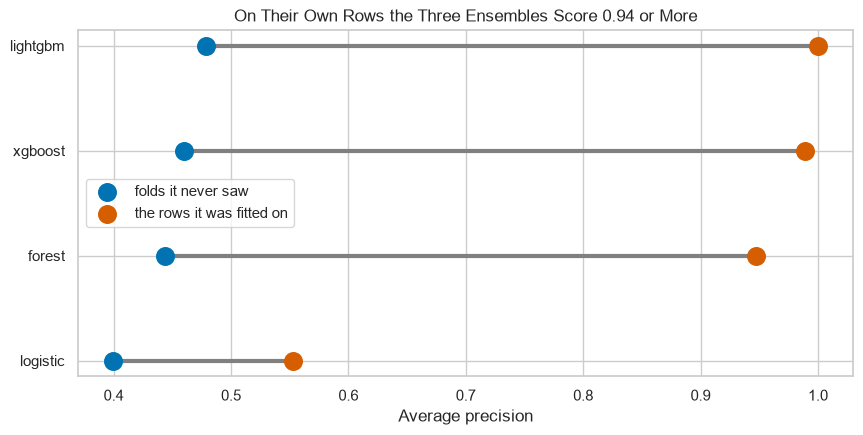

In [53]:
# one dumbbell per model: its fold mean and its training-row score, joined
plt.figure(figsize=(10, 4.5))
plt.hlines(gap_table.index, gap_table["folds"], gap_table["training rows"], color="gray", linewidth=3)
plt.scatter(gap_table["folds"], gap_table.index, s=160, color="C0", zorder=3, label="folds it never saw")
plt.scatter(gap_table["training rows"], gap_table.index, s=160, color="C3", zorder=3, label="the rows it was fitted on")
plt.xlabel("Average precision")
plt.title("On Their Own Rows the Three Ensembles Score 0.94 or More")
plt.legend(loc="center left")
plt.show()

On the rows it was fitted on LightGBM scores 1.0000, XGBoost 0.9893 and the forest 0.9470: memory, as Day 11's fitted folds showed.

The logistic scores 0.5531 there, with the smallest gap to its folds.

In [54]:
check("Q19 LightGBM on its own rows", q19_lightgbm, "413880f26e99", places=4)
check("Q19 logistic on its own rows", q19_logistic, "5bf4b8f51dc4", places=4)

Q19 LightGBM on its own rows: correct
Q19 logistic on its own rows: correct


## The Choice

Q. Which model goes forward, by the criterion set before any model was fitted? Store its key in `models` in `q20_choice`, and write one reason a line.

In [55]:
# the criterion and two more readings side by side: fold AP, rows flagged for 0.70, and the own-row gap
q20_choice = "lightgbm"
pd.DataFrame({"fold AP": gap_table["folds"], "flagged for 0.70": summary["flagged"], "own rows minus folds": gap_table["training rows"] - gap_table["folds"]})

,fold AP,flagged for 0.70,own rows minus folds
logistic,0.3998,447,0.1533
forest,0.4439,420,0.5031
xgboost,0.4599,382,0.5294
lightgbm,0.4785,374,0.5215


LightGBM has the highest fold average precision, 0.4785, the criterion itself.

It flags the fewest training rows for a recall of 0.70, 374.

Its own-row score is memory and plays no part in the choice; every setting and the treatment of the rare class were chosen on folds.

In [56]:
check("Q20 the choice", q20_choice, "9d9041d8ad05")

Q20 the choice: correct


**One model goes forward, chosen before one test row is scored.**

# The Test Rows, Opened Once

**Predict 3**

Out of fold, LightGBM's threshold of 0.0039 catches 124 of the 176 training bankruptcies, 70.5 percent.

Q. How many of the 44 test bankruptcies will it flag?

**Predict 4**

Q. Which of the four models will have the highest average precision on the test rows, and what will it be? Write down a name and a number.

## The Test Table

Q. Score the four models on the test rows in one table `test_comp`, each at its threshold, and keep their test outputs in a dictionary `test_outputs`. Store LightGBM's test bankruptcies flagged and test average precision in `q21_caught` and `q21_ap` (4 decimals), and the key of the model highest on test average precision in `q21_best`.

Q. Draw the four confusion matrices in Course 4's colours.

In [57]:
# the test rows, opened once: each model at the threshold chosen out of fold
test_comp = pd.concat([model_performance_classification(models[name], X_test, y_test, thresholds[name]).T for name in models], axis=1)
test_comp.columns = list(models)
test_outputs = {name: models[name].predict_proba(X_test)[:, 1] for name in models}
q21_caught = ((test_outputs["lightgbm"] >= thresholds["lightgbm"]) & (y_test == 1)).sum()
q21_ap, q21_best = test_comp.loc["Average precision", "lightgbm"], test_comp.loc["Average precision"].idxmax()
print("LightGBM flags", q21_caught, "of", y_test.sum(), "test bankruptcies")
test_comp

LightGBM flags 32 of 44 test bankruptcies


,logistic,forest,xgboost,lightgbm
Average precision,0.5262,0.5050,0.5107,0.4867
ROC AUC,0.9538,0.9541,0.9484,0.9543
Accuracy,0.9304,0.9399,0.9457,0.9311
Recall,0.7727,0.7727,0.7727,0.7273
Precision,0.2857,0.3208,0.3469,0.2807
F1,0.4172,0.4533,0.4789,0.4051


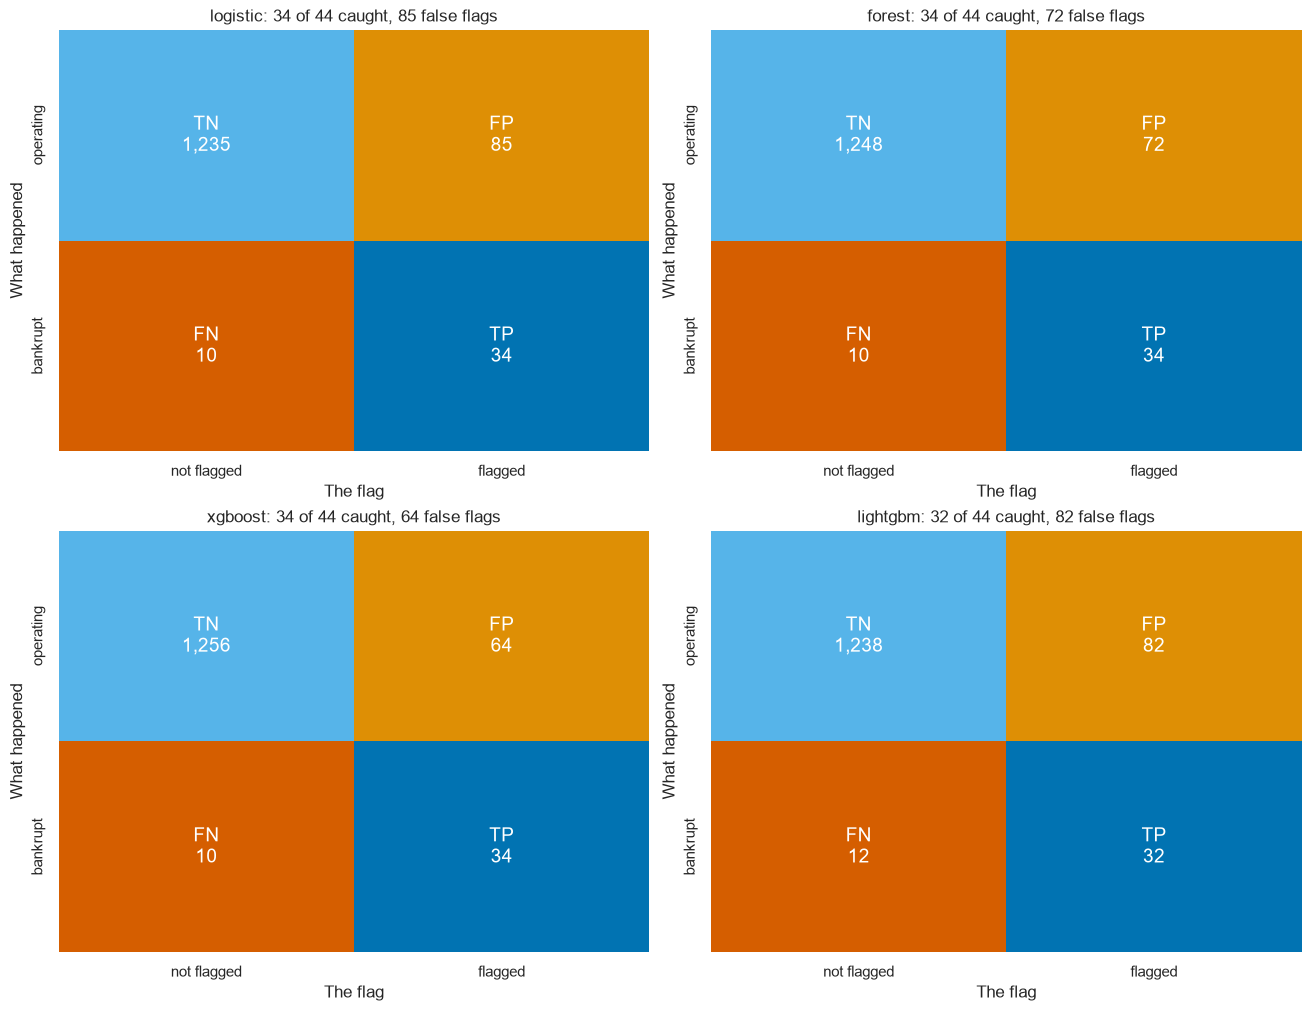

In [58]:
# the four test matrices, each cell in Course 4's colour with its name and count
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
for ax, name in zip(axes.ravel(), models):
    tn, fp, fn, tp = confusion_matrix(y_test, test_outputs[name] >= thresholds[name]).ravel()
    labels = [[f"TN\n{tn:,}", f"FP\n{fp:,}"], [f"FN\n{fn:,}", f"TP\n{tp:,}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged", "flagged"], yticklabels=["operating", "bankrupt"])
    ax.set(xlabel="The flag", ylabel="What happened", title=f"{name}: {tp} of 44 caught, {fp} false flags")
plt.show()

LightGBM catches 32 of the 44, a recall of 0.7273, with 82 false flags; its test average precision is 0.4867 and its ROC AUC 0.9543.

The logistic, last on the folds, is first on the test rows at 0.5262, with XGBoost at 0.5107 and the forest at 0.5050.

The other three each catch 34, with 64 to 85 false flags.

In [59]:
check("Q21 test bankruptcies flagged", q21_caught, "2d82ca9df415", places=0)
check("Q21 test average precision", q21_ap, "eb5dde24d64a", places=4)
check("Q21 highest on the test rows", q21_best, "1f19067b48f6")

Q21 test bankruptcies flagged: correct
Q21 test average precision: correct
Q21 highest on the test rows: correct


**Predict 5**

On 6,000 card accounts with 1,327 defaults, Day 10's intervals were about 0.028 wide on ROC AUC and 0.059 on average precision (its Exercise 2).

Q. Resample the 1,364 test rows 1,000 times. How wide will the 95 percent interval of LightGBM's test average precision be? Write down a number.

## How Sure Can Anyone Be?

Q. With Day 10's `rng = np.random.default_rng(SEED)` and `draws = rng.choice(1364, size=(1000, 1364))`, score each model's test average precision on every resample, in a table `boot_ap`. Store LightGBM's 95 percent interval in `q22_low` and `q22_high`, and that of LightGBM minus the logistic, paired, in `q22_pair_low` and `q22_pair_high` (4 decimals).

An **estimation plot** sets each score with its interval beside each paired difference with its interval, against zero.

Q. Draw one, with the test scores, their intervals and the fold means as rings on the left, and LightGBM minus each model as a half violin with its interval as a bar on the right.

In [60]:
# 1,000 resamples of the 1,364 test positions, and every model's average precision on each
rng = np.random.default_rng(SEED)
draws = rng.choice(1364, size=(1000, 1364))
y_values = y_test.to_numpy()
boot_ap = pd.DataFrame()
for name in models:
    boot_ap[name] = [average_precision_score(y_values[d], test_outputs[name][d]) for d in draws]

# LightGBM minus each other model on the same resamples, then every 95 percent interval
gaps = pd.DataFrame({name: boot_ap["lightgbm"] - boot_ap[name] for name in ["logistic", "forest", "xgboost"]})
intervals = pd.concat([boot_ap, gaps.add_prefix("lightgbm minus ")], axis=1).quantile([0.025, 0.975]).T
q22_low, q22_high = intervals.loc["lightgbm"]
q22_pair_low, q22_pair_high = intervals.loc["lightgbm minus logistic"]
intervals

,0.0250,0.9750
logistic,0.3787,0.6628
forest,0.3673,0.6494
xgboost,0.3626,0.6738
lightgbm,0.3478,0.6609
lightgbm minus logistic,-0.1531,0.0999
lightgbm minus forest,-0.1040,0.0823
lightgbm minus xgboost,-0.0868,0.0498


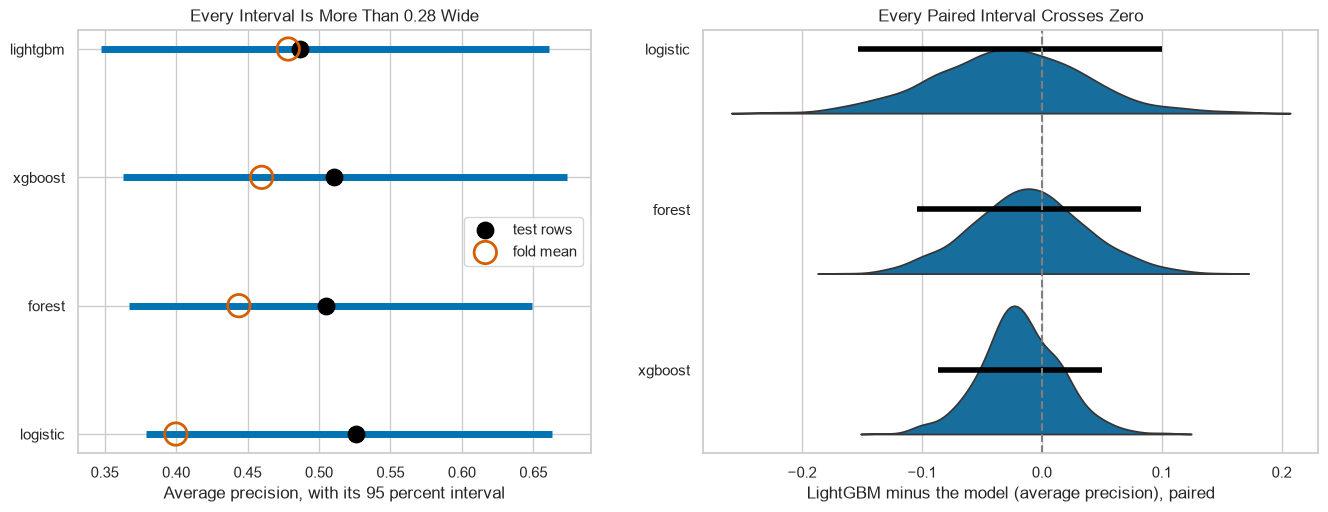

In [61]:
# left: each test score, its interval, its fold mean as a ring; right: the paired differences against zero
fig, (left, right) = plt.subplots(1, 2, figsize=(16, 5.5), width_ratios=[1, 1.2])
left.hlines(list(models), intervals.loc[list(models), 0.025], intervals.loc[list(models), 0.975], linewidth=5, color="C0")
left.scatter(test_comp.loc["Average precision"], list(models), s=140, color="black", zorder=3, label="test rows")
left.scatter(fold_ap.mean(), list(models), s=260, facecolor="none", edgecolor="C3", linewidth=2, zorder=3, label="fold mean")
left.set(xlabel="Average precision, with its 95 percent interval", title="Every Interval Is More Than 0.28 Wide")
left.legend(loc="center right")
sns.violinplot(data=gaps.melt(var_name="model", value_name="gap"), x="gap", y="model", split=True, inner=None, color="C0", ax=right)
right.hlines(range(3), intervals.loc[gaps.add_prefix("lightgbm minus ").columns, 0.025], intervals.loc[gaps.add_prefix("lightgbm minus ").columns, 0.975], color="black", linewidth=4)
right.axvline(0, color="gray", linestyle="--")
right.set(xlabel="LightGBM minus the model (average precision), paired", ylabel="", title="Every Paired Interval Crosses Zero")
plt.show()

LightGBM's test score could sit anywhere from 0.3478 to 0.6609 on these rows: an interval 0.3131 wide, more than five times Day 10's 0.059 on average precision.

Every model's interval overlaps every other, and each fold mean sits inside its own model's interval.

Paired, LightGBM minus the logistic runs from -0.1531 to 0.0999, and the other two differences cross zero as well.

**The choice stands: switching to the logistic now would choose on the test rows.**

In [62]:
check("Q22 LightGBM low", q22_low, "88c13afdaf94", places=4)
check("Q22 LightGBM high", q22_high, "e2bf2001901d", places=4)
check("Q22 paired low", q22_pair_low, "43c03d1852f7", places=4)
check("Q22 paired high", q22_pair_high, "c242294b68c0", places=4)

Q22 LightGBM low: correct
Q22 LightGBM high: correct
Q22 paired low: correct
Q22 paired high: correct


## Which Bankruptcies Each Model Catches

Q. For each test bankruptcy, note which models flag it, in a table `caught`, one column per model. Store how many all four flag and how many none flags in `q23_all` and `q23_none`.

In [63]:
# for each test bankruptcy, which models flag it at their thresholds
went = y_values == 1
caught = pd.DataFrame({name: (test_outputs[name] >= thresholds[name])[went] for name in models})
q23_all, q23_none = caught.all(axis=1).sum(), (~caught.any(axis=1)).sum()
print("All four:", q23_all, "  None:", q23_none)
caught.value_counts()

All four: 29   None: 5


logistic  forest  xgboost  lightgbm
True      True    True     True        29
False     False   False    False        5
True      False   False    False        4
False     True    True     True         3
True      True    True     False        1
False     True    False    False        1
          False   True     False        1
Name: count, dtype: int64

29 of the 44 are caught by all four models and 5 by none; the other 10 split the models.

**With 44 bankruptcies the test rows cannot rank four models the folds could not settle either: the honest answer is the interval.**

In [64]:
check("Q23 caught by all four", q23_all, "3789e3ae8563", places=0)
check("Q23 caught by none", q23_none, "c47017325a12", places=0)

Q23 caught by all four: correct
Q23 caught by none: correct


# What the Model Leans On

Day 14 found that SHAP values on fitted rows describe memory, so the chosen model is described on the 1,364 test rows it never fitted.
A SHAP value is a contribution to a row's log-odds relative to the model's average, never a reason.

![Explained on rows it never fitted. LightGBM is fitted once on the 5,455 training rows. Its SHAP values on those rows describe what it remembers of them, Day 14's finding. Its SHAP values on the 1,364 test rows, which no fit and no choice ever used, describe what it leans on for rows it never saw. Each SHAP value is a contribution to a row's log-odds relative to the model's average, never a reason.](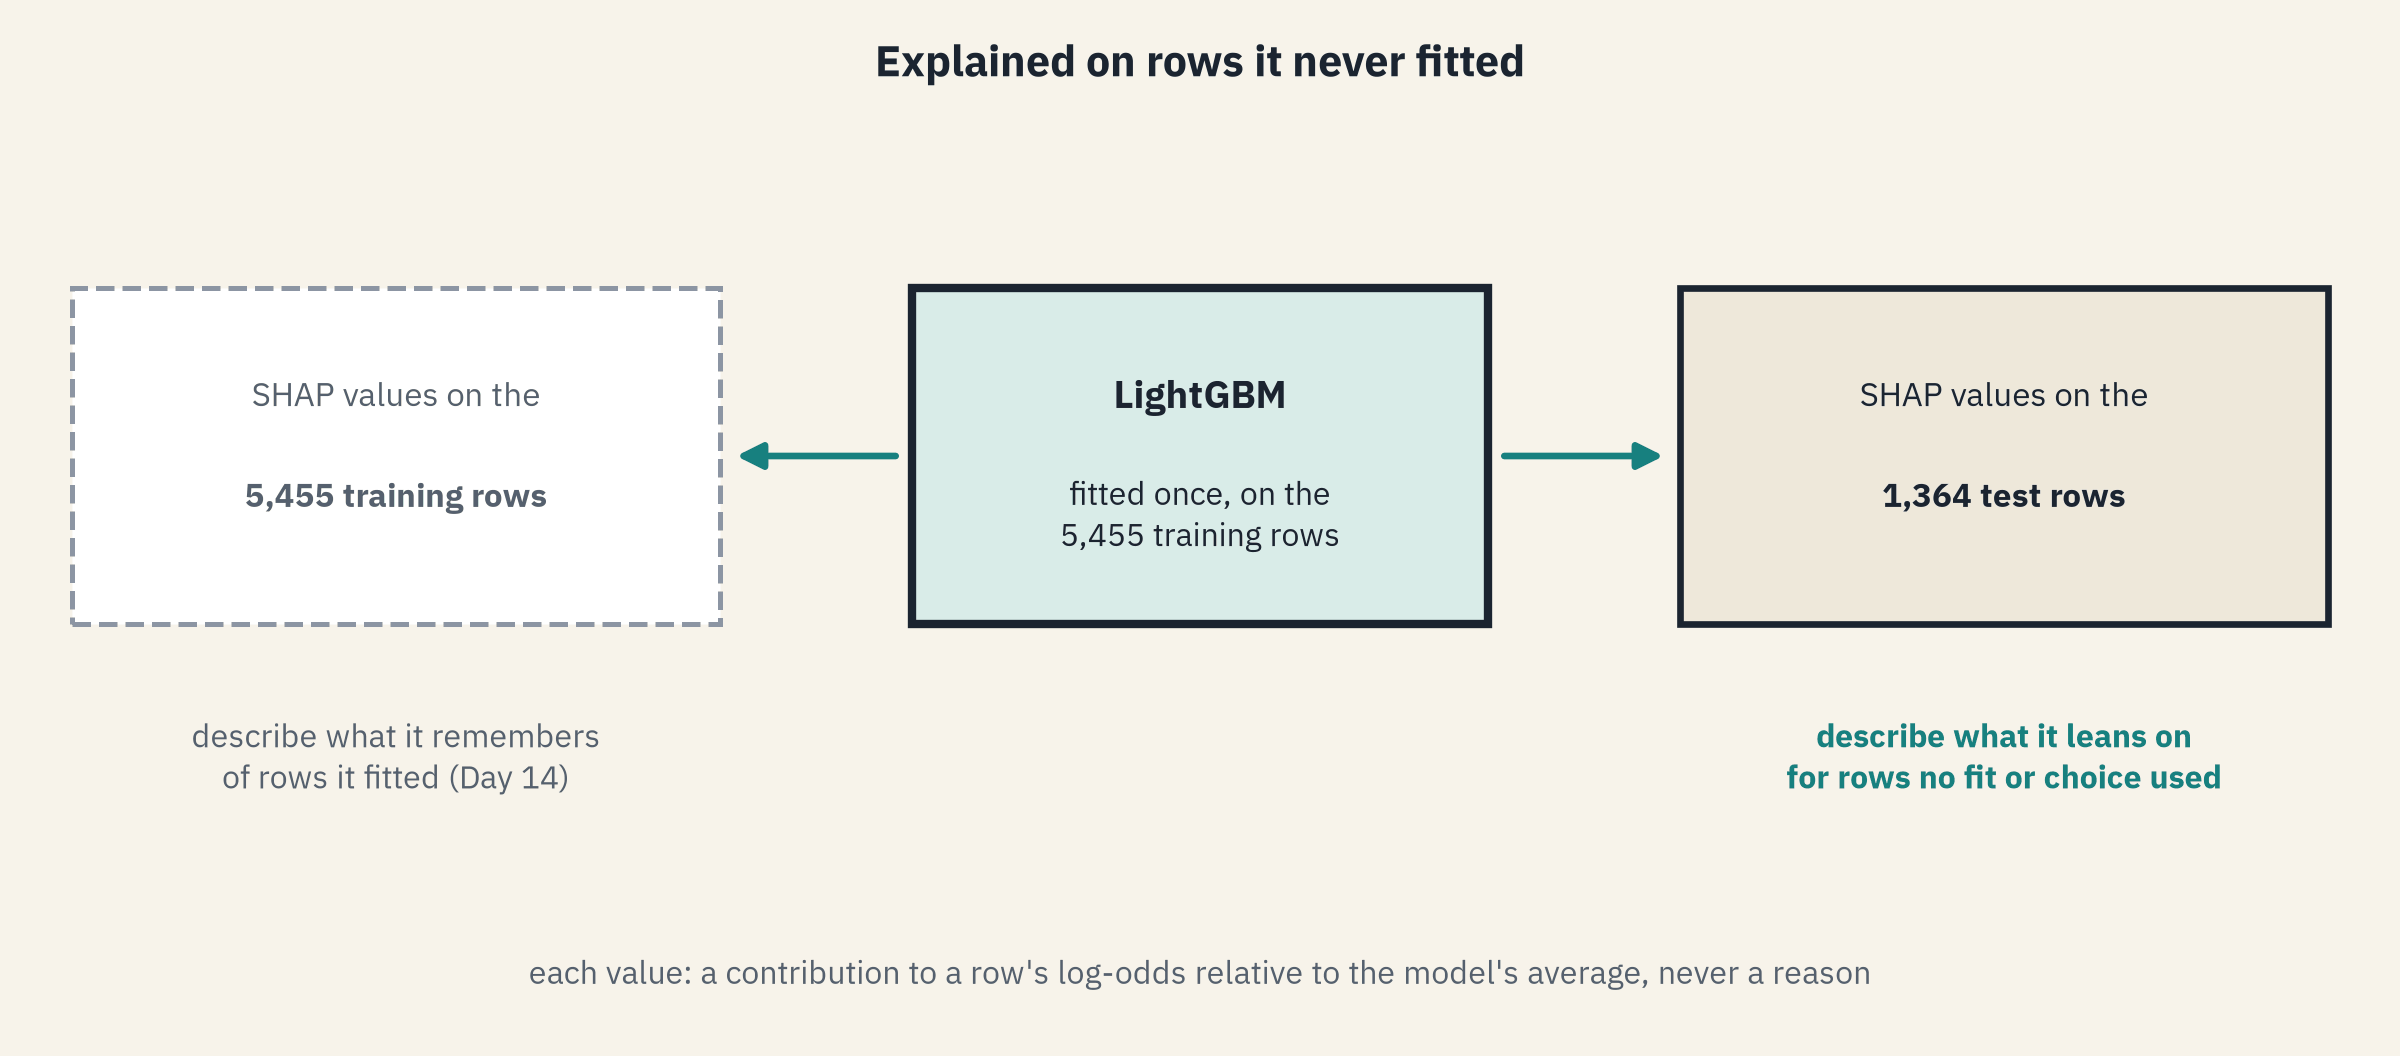)

## SHAP Values on the Test Rows

Q. Explain the fitted LightGBM on `X_test` with Day 14's `shap.TreeExplainer`, as `shap_test`. Store the base value in `q24_base` (4 decimals), the feature with the largest mean absolute SHAP value and that value in `q24_top` and `q24_top_value` (4 decimals), and how many of the test rows' top ten are also top ten on the training rows in `q24_shared`.

Q. Draw the beeswarm of the top ten with `shap.summary_plot(..., max_display=10, rng=SEED, show=False)`.

In [65]:
# the SHAP values on the test rows, and the check that they add up to the model's log-odds
explainer = shap.TreeExplainer(models["lightgbm"])
shap_test = explainer(X_test)
rebuilt = shap_test.base_values + shap_test.values.sum(axis=1)
print("Largest gap from the log-odds:", f"{np.abs(rebuilt - models['lightgbm'].predict(X_test, raw_score=True)).max():.1e}")

# the mean absolute SHAP value of each feature, on the test rows and on the training rows
on_test = pd.Series(np.abs(shap_test.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
on_train = pd.Series(np.abs(explainer(X_train).values).mean(axis=0), index=X_train.columns).sort_values(ascending=False)
q24_base, q24_top, q24_top_value = shap_test.base_values[0], on_test.index[0], on_test.iloc[0]
q24_shared = len(set(on_test.index[:10]) & set(on_train.index[:10]))
print("Base value:", round(q24_base, 4), "log-odds  Top:", q24_top, round(q24_top_value, 4), "  Shared in the top ten:", q24_shared)

Largest gap from the log-odds: 2.0e-14
Base value: -10.1132 log-odds  Top: Borrowing dependency 0.3477   Shared in the top ten: 10


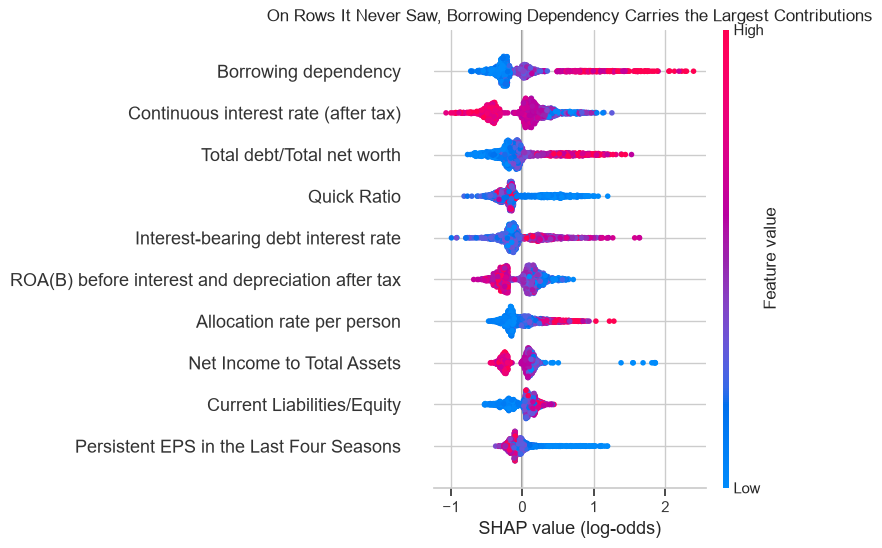

In [66]:
# every test row's SHAP value in the ten features the model leans on most
shap.summary_plot(shap_test, max_display=10, rng=SEED, show=False)
plt.xlabel("SHAP value (log-odds)")
plt.title("On Rows It Never Saw, Borrowing Dependency Carries the Largest Contributions")
plt.show()

The base value plus a row's SHAP values gives its log-odds for every test row, as Day 14 found on its rows.

`Borrowing dependency` has the largest mean absolute SHAP value on the test rows, 0.3477 log-odds.

The same ten features lead on the training rows: the ranking of features holds, while Day 14 showed a single row's story can change.

All of it is association in this file.

In [67]:
check("Q24 base value", q24_base, "df66450a246e", places=4)
check("Q24 top feature", q24_top, "41152d38bd47")
check("Q24 its mean absolute SHAP value", q24_top_value, "ff6011615fb0", places=4)
check("Q24 shared in the top ten", q24_shared, "e5ab4286fa2b", places=0)

Q24 base value: correct
Q24 top feature: correct
Q24 its mean absolute SHAP value: correct
Q24 shared in the top ten: correct


## Split Counts Against SHAP

Q. Keep LightGBM's split counts, Day 9's `booster_.feature_importance("split")`, in a Series `splits`. How many of the split top ten and of the SHAP top ten are in `two_scale`? Store them in `q25_split_two_scale` and `q25_shap_two_scale`, and the most split feature in `q25_top_split`.

Q. Draw a slopegraph from rank by split count to rank by mean absolute SHAP value for the features in either top ten, two-scale features in colour.

In [68]:
# the times each feature is used to split, across the 100 trees
splits = pd.Series(models["lightgbm"].booster_.feature_importance("split"), index=X_train.columns).sort_values(ascending=False)
q25_split_two_scale = len([name for name in splits.index[:10] if name in two_scale])
q25_shap_two_scale = len([name for name in on_test.index[:10] if name in two_scale])
q25_top_split = splits.index[0]
print("Two-scale features in the split top ten:", q25_split_two_scale, "  in the SHAP top ten:", q25_shap_two_scale)
print("Most split:", q25_top_split, splits.iloc[0], "times")

Two-scale features in the split top ten: 9   in the SHAP top ten: 4
Most split: Interest-bearing debt interest rate 114 times


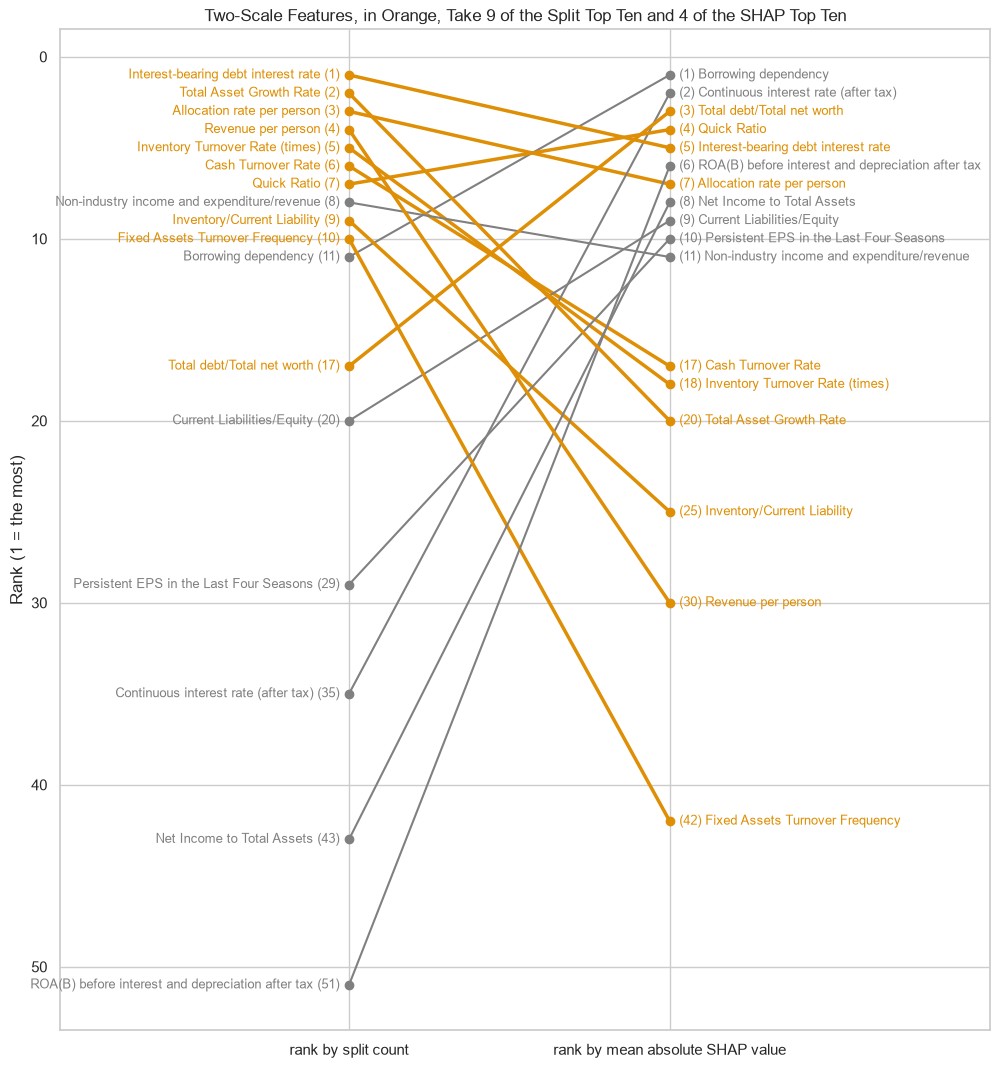

In [69]:
# each feature's rank on both measures (1 = the most; ties in split counts broken by order), for either top ten
ranks = pd.DataFrame({"split count": splits.rank(ascending=False, method="first"), "SHAP": on_test.rank(ascending=False, method="first")})
shown = ranks[(ranks <= 10).any(axis=1)].astype(int)
plt.figure(figsize=(12, 13))
for name, row in shown.iterrows():
    colour = "C1" if name in two_scale else "gray"
    plt.plot([0, 1], [row["split count"], row["SHAP"]], marker="o", color=colour, linewidth=2.5 if name in two_scale else 1.5)
    plt.text(-0.03, row["split count"], f"{name} ({row['split count']})", ha="right", va="center", fontsize=9, color=colour)
    plt.text(1.03, row["SHAP"], f"({row['SHAP']}) {name}", ha="left", va="center", fontsize=9, color=colour)
plt.gca().invert_yaxis()
plt.xticks([0, 1], ["rank by split count", "rank by mean absolute SHAP value"])
plt.xlim(-0.9, 2.0)
plt.ylabel("Rank (1 = the most)")
plt.title("Two-Scale Features, in Orange, Take 9 of the Split Top Ten and 4 of the SHAP Top Ten")
plt.show()

9 of the ten most split features are two-scale features, against 4 of the SHAP top ten; `Interest-bearing debt interest rate` is split on 114 times.

A split count rewards a feature with many places to cut, wherever the cut sits, and says nothing of how far a split moves the log-odds: a fact about the measure.

In [70]:
check("Q25 two-scale in the split top ten", q25_split_two_scale, "484ebff6fdbd", places=0)
check("Q25 two-scale in the SHAP top ten", q25_shap_two_scale, "91ff364ccd0c", places=0)
check("Q25 most split feature", q25_top_split, "a4fd9d831b88")

Q25 two-scale in the split top ten: correct
Q25 two-scale in the SHAP top ten: correct
Q25 most split feature: correct


# Where the Model Fails

## The Misses

Q. Which test bankruptcies does LightGBM miss at its threshold? Store how many, the highest probability among them (5 decimals) and its row label in `q26_missed`, `q26_highest` and `q26_row`, and compare the median `Total debt/Total net worth` of the missed, caught and operating test rows.

Q. Draw that row's waterfall (Day 14).

In [71]:
# the bankruptcies under the threshold, and the one the model put highest
lgbm_test = pd.Series(test_outputs["lightgbm"], index=X_test.index)
missed = (y_test == 1) & (lgbm_test < thresholds["lightgbm"])
q26_missed, q26_highest, q26_row = missed.sum(), lgbm_test[missed].max(), lgbm_test[missed].idxmax()
print(q26_missed, "missed; the highest probability among them:", round(q26_highest, 5), "at row", q26_row)

# the median Total debt/Total net worth of each group of test rows
group = np.where(y_test == 0, "operating", np.where(missed, "missed", "caught"))
X_test.groupby(group)["Total debt/Total net worth"].median()

12 missed; the highest probability among them: 0.00297 at row 2392


caught      0.0191
missed      0.0075
operating   0.0054
Name: Total debt/Total net worth, dtype: float64

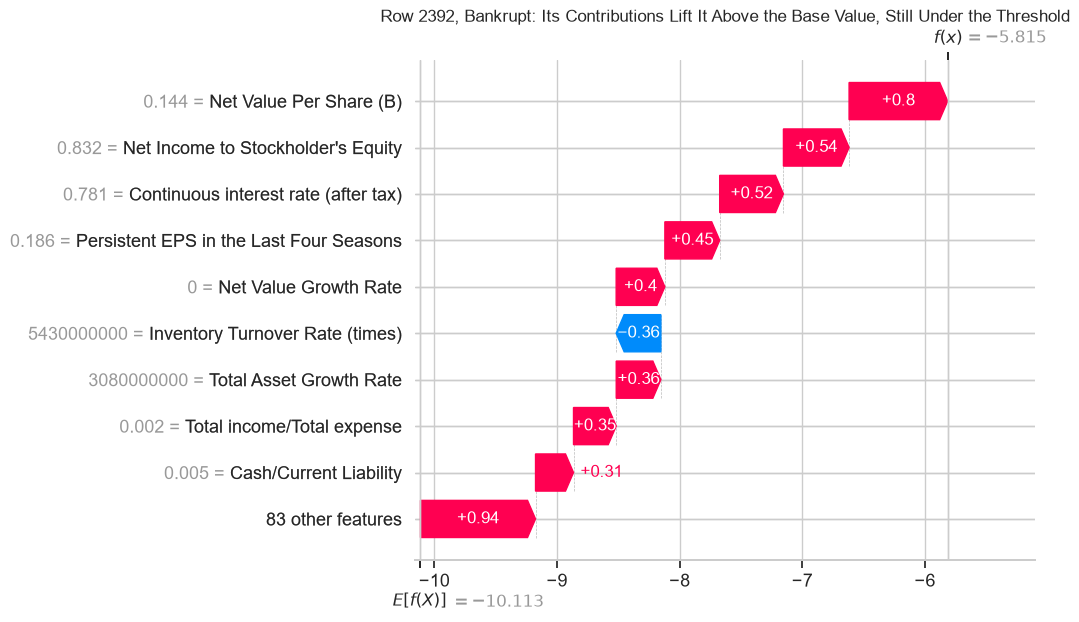

In [72]:
# the missed row's waterfall: from the base value, its nine largest contributions, the other 83 in one bar
shap.plots.waterfall(shap_test[X_test.index.get_loc(q26_row)], max_display=10, show=False)
plt.title(f"Row {q26_row}, Bankrupt: Its Contributions Lift It Above the Base Value, Still Under the Threshold")
plt.show()

12 bankruptcies are missed; the highest of them sits at a probability of 0.00297, under the threshold of 0.0039.

On `Total debt/Total net worth` the missed rows' median, 0.0075, sits nearer the operating rows' 0.0054 than the caught rows' 0.0191.

On this feature, the third the model leans on most, the misses look like operating rows; the threshold stays where the folds set it.

In [73]:
check("Q26 missed", q26_missed, "4cfb7a5305bd", places=0)
check("Q26 highest probability missed", q26_highest, "0324e0f45276", places=5)
check("Q26 its row", q26_row, "0b569c54a2b3", places=0)

Q26 missed: correct
Q26 highest probability missed: correct
Q26 its row: correct


## What the Probabilities Add Up To

Q. Add up LightGBM's out-of-fold probabilities on the training rows, and its probabilities on the test rows. Store the sums in `q27_oof` and `q27_test` (1 decimal), against 176 and 44 bankruptcies.

In [74]:
# the probabilities added up, against the bankruptcies they cover
q27_oof, q27_test = out_of_fold["lightgbm"].sum(), test_outputs["lightgbm"].sum()
print("Out of fold:", round(q27_oof, 1), "against", y_train.sum(), "  Test rows:", round(q27_test, 1), "against", y_test.sum())

Out of fold: 76.0 against 176   Test rows: 24.0 against 44


The probabilities add up to 76.0 where 176 training rows went bankrupt, and 24.0 where 44 test rows did: short, as Day 13 found the unweighted booster short on the Polish file (232 against 326).

They rank well and run low, so a single one is not read as a frequency; Exercise 2 recalibrates them.

In [75]:
check("Q27 out-of-fold sum", q27_oof, "326a8909b574", places=1)
check("Q27 test sum", q27_test, "77d60f04e03c", places=1)

Q27 out-of-fold sum: correct
Q27 test sum: correct


# Insights and Conclusion

## The Description

Q. Write `description`, a few sentences in one string: how well the chosen model ranks the test rows and how sure anyone can be, where it is wrong, what the data cannot support, and what was not tested.

In [76]:
# the description, as one string
description = (
    "On the 1,364 test rows LightGBM ranks the bankrupt rows with average precision 0.4867 and ROC AUC 0.9543, and at the threshold chosen out of fold it flags 32 of the 44 bankruptcies with 82 false flags. "
    "With 44 bankruptcies its score could sit anywhere from 0.35 to 0.66, and no paired interval separates it from the other three models. "
    "It misses 12 bankrupt rows, which sit nearer the operating rows than the caught ones on Total debt/Total net worth, a feature it leans on. "
    "The file is one market from 1999 to 2009, with bankruptcy defined by exchange regulation, no horizon, no company identifier and values on two scales the page does not explain. "
    "Order in time, another period, and the cost of an error were not tested, and the output describes this file, not any company's credit."
)
print(description)

On the 1,364 test rows LightGBM ranks the bankrupt rows with average precision 0.4867 and ROC AUC 0.9543, and at the threshold chosen out of fold it flags 32 of the 44 bankruptcies with 82 false flags. With 44 bankruptcies its score could sit anywhere from 0.35 to 0.66, and no paired interval separates it from the other three models. It misses 12 bankrupt rows, which sit nearer the operating rows than the caught ones on Total debt/Total net worth, a feature it leans on. The file is one market from 1999 to 2009, with bankruptcy defined by exchange regulation, no horizon, no company identifier and values on two scales the page does not explain. Order in time, another period, and the cost of an error were not tested, and the output describes this file, not any company's credit.


The description says what the model leans on and how well it ranks, never why a company failed or what will happen to one.

**A model describes the file it was fitted on.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Describe a new file's constants, copies, near-copies and scales before any model sees it.
* Compare models on folds and score a search with nested cross-validation.
* Choose class weights, resampling and a threshold from out-of-fold outputs.
* Open the test rows once and put an interval, paired or not, on each score.
* Describe a model with SHAP values on rows it never fitted.

## Exercises

`check()` from Setting Up marks each answer.

### Exercise 1

**A Recall Target of 0.80**

Q. Read LightGBM's out-of-fold threshold for a recall of 0.80 with `threshold_for_recall`, and count the training rows it flags. Store them in `ex1_threshold` (4 decimals) and `ex1_flagged`.

In [77]:
# Day 10's rule on LightGBM's out-of-fold probabilities, for a recall of 0.80
ex1_threshold = threshold_for_recall(y_train, out_of_fold["lightgbm"], 0.80)
ex1_flagged = (out_of_fold["lightgbm"] >= ex1_threshold).sum()
print(round(ex1_threshold, 4), " Flagged:", ex1_flagged, " Precision:", round(precision_score(y_train, out_of_fold["lightgbm"] >= ex1_threshold), 4))

0.0008  Flagged: 585  Precision: 0.241


Asking for 0.80 drops the threshold from 0.0039 to 0.0008 and the flags rise from 374 to 585; under a quarter of them are bankrupt.

In [78]:
check("Exercise 1 threshold", ex1_threshold, "9e4f6222d1cf", places=4)
check("Exercise 1 flagged", ex1_flagged, "e6d1cb81787c", places=0)

Exercise 1 threshold: correct
Exercise 1 flagged: correct


### Exercise 2

**Probabilities That Add Up**

Q. Score Day 13's `CalibratedClassifierCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), method="isotonic", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)` out of fold on `folds`. Store the sum of its probabilities (1 decimal) and its Brier score (4 decimals) in `ex2_sum` and `ex2_brier`.

In [79]:
# isotonic recalibration inside each outer training part, then every training row scored out of fold
calibrated = CalibratedClassifierCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), method="isotonic",
                                    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)
recalibrated = cross_val_predict(calibrated, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
ex2_sum, ex2_brier = recalibrated.sum(), brier_score_loss(y_train, recalibrated)
print("Sum:", round(ex2_sum, 1), "against", y_train.sum(), " Brier:", round(ex2_brier, 4), "against", round(brier_score_loss(y_train, out_of_fold["lightgbm"]), 4))
print("Pooled average precision:", round(average_precision_score(y_train, recalibrated), 4), "against", round(average_precision_score(y_train, out_of_fold["lightgbm"]), 4))

Sum: 176.1 against 176  Brier: 0.0229 against 0.0256
Pooled average precision: 0.4352 against 0.4656


Recalibrated, the probabilities add up to 176.1 against 176 bankruptcies, and the Brier score falls from 0.0256 to 0.0229.

The ranking pays for it: pooled average precision falls from 0.4656 to 0.4352.

In [80]:
check("Exercise 2 sum", ex2_sum, "b162cf9fad0c", places=1)
check("Exercise 2 Brier score", ex2_brier, "36552865f46e", places=4)

Exercise 2 sum: correct
Exercise 2 Brier score: correct


### Exercise 3: AI check

**The File's Own Order**

You asked an AI assistant for a function that splits the rows 80/20.
This came back.
It runs, and its comment sounds careful.
Test it, then find the one bug.

In [81]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def split_rows(frame):
    # split 80/20 and keep the file's order, so the split is the same on every run
    return train_test_split(frame[FEATURES], frame[TARGET], test_size=0.2, shuffle=False)

In [82]:
# the test: the test rows' bankrupt share must sit within 0.25 percentage points of the whole file's
ai_train, ai_test, ai_y_train, ai_y_test = split_rows(ratios)
test_share, file_share = ai_y_test.mean() * 100, ratios[TARGET].mean() * 100
assert abs(test_share - file_share) < 0.25, f"the test rows are {test_share:.2f} percent bankrupt against {file_share:.2f} in the file"

AssertionError: the test rows are 1.61 percent bankrupt against 3.23 in the file

Q. Fix the function: shuffle, stratify on the outcome and use the course seed. Store the bankrupt share of its test rows, in percent, in `ex3_share` (2 decimals).

In [83]:
# the fix: a shuffled, stratified split with the seed is the same on every run too
def split_rows(frame):
    return train_test_split(frame[FEATURES], frame[TARGET], test_size=0.2, stratify=frame[TARGET], random_state=SEED)

fixed_train, fixed_test, fixed_y_train, fixed_y_test = split_rows(ratios)
ex3_share = fixed_y_test.mean() * 100
print("The assistant's test rows:", ai_y_test.sum(), "bankrupt of", len(ai_y_test))
print("The fixed test rows:", round(ex3_share, 2), "percent bankrupt, against", round(ratios[TARGET].mean() * 100, 2), "in the file")

The assistant's test rows: 22 bankrupt of 1364
The fixed test rows: 3.23 percent bankrupt, against 3.23 in the file


The assistant's split kept the file's last fifth as test rows, and the file's order carries the outcome: 22 bankrupt test rows of 1,364, 1.61 percent.

Its comment's reason does not hold: the seed already makes a shuffled split the same on every run.

Nothing in its output looks wrong; only a test of the share on each side finds it.

In [84]:
check("Exercise 3 test share", ex3_share, "de80c5eaf100", places=2)

Exercise 3 test share: correct


## Congratulations!

You ran the whole course on a file nobody had shown you, and the work was yours.
You found a constant, copied pairs, two scales and an order that carries the outcome, and kept the test rows closed through it all.
You chose every setting on folds, opened the test rows once, and gave the interval as the honest answer.
Course 5B turns to dated series, starting with the gaps in Treasury yields, and Course 6's capstone brings these 5,455 training rows back.

[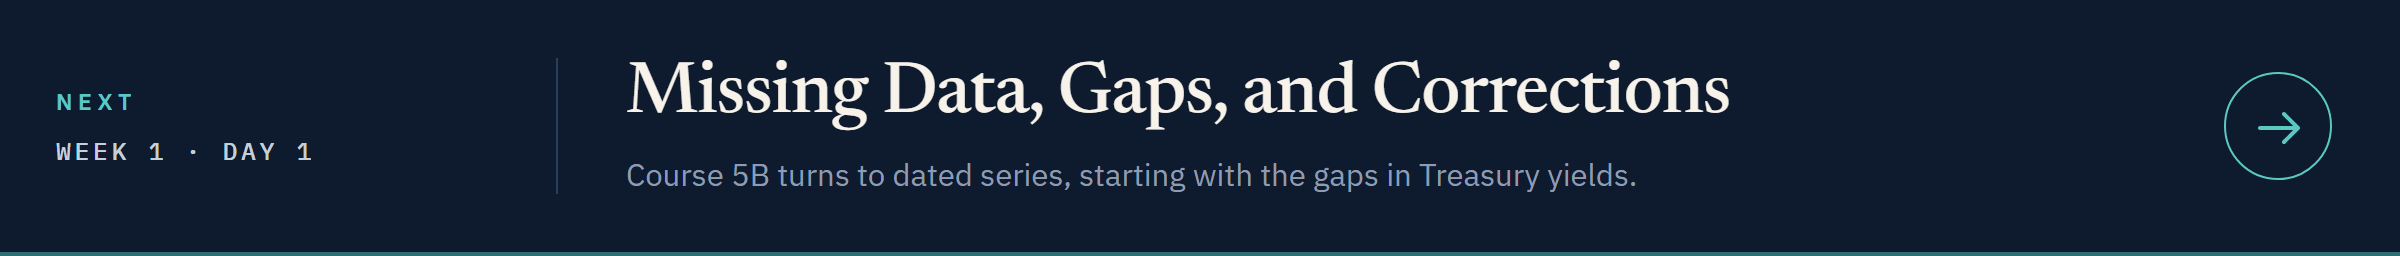](../../../course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections.ipynb)